<a href="https://colab.research.google.com/github/Chetalam/cnn-skin-cancer-classification/blob/main/notebooks/05_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 — CNN Transfer Learning

Train MobileNetV2, EfficientNet-B0 and ResNet50 using the grouped splits from notebook 4. Class order is BCC, Melanoma, SCC. Use training-only class weights and augmentation. Select model checkpoints using validation macro F1. Reserve the test set for notebook 6.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import json
import shutil
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import display

print('TensorFlow:', tf.__version__)
print('Keras:', getattr(tf.keras, '__version__', 'bundled with TensorFlow'))
gpus = tf.config.list_physical_devices('GPU')
print('Available GPUs:', gpus)
if not gpus:
    raise RuntimeError('Enable the T4 GPU before continuing.')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
HEAD_EPOCHS = 6
FINE_TUNE_EPOCHS = 8
CLASS_NAMES = ['BCC', 'Melanoma', 'SCC']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
PROJECT_ROOT = Path('/content/drive/MyDrive/cnn-skin-cancer-classification')
SPLIT_ROOT = PROJECT_ROOT / 'Datasets' / 'Splits'
MODEL_ROOT = PROJECT_ROOT / 'Models' / 'Transfer_Learning'
REPORT_ROOT = PROJECT_ROOT / 'Reports' / 'Training'
LOCAL_ROOT = Path('/content/skin_cancer_training_images')
for folder in [MODEL_ROOT, REPORT_ROOT, LOCAL_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

def write_json(path, value):
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2), encoding='utf-8')
    temporary.replace(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
Keras: 3.13.2
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
frames = {}
manifest_hashes = {}
for split in ['train', 'validation', 'test']:
    path = SPLIT_ROOT / f'{split}_metadata.csv'
    if not path.is_file():
        raise FileNotFoundError(path)
    manifest_hashes[split] = hashlib.sha256(path.read_bytes()).hexdigest()
    frame = pd.read_csv(path, dtype={'patient_id': 'string', 'lesion_id': 'string'})
    required = {'dataset', 'image_id', 'class_label', 'image_path', 'image_hash', 'group_id', 'label_index', 'split'}
    if not required.issubset(frame.columns):
        raise ValueError(f'{split}: required split columns are missing.')
    if not frame['split'].eq(split).all():
        raise ValueError(f'{split}: incorrect split assignments.')
    if set(frame['class_label']) != set(CLASS_NAMES):
        raise ValueError(f'{split}: expected all three classes.')
    expected_labels = frame['class_label'].map(CLASS_TO_INDEX)
    if not expected_labels.eq(frame['label_index']).all():
        raise ValueError(f'{split}: class order differs from notebook 4.')
    frames[split] = frame

combined = pd.concat(frames.values(), ignore_index=True)
assert len(combined) == 2703
assert not combined.duplicated(['dataset', 'image_id']).any()
assert combined.groupby('group_id')['split'].nunique().max() == 1
assert combined.groupby('image_hash')['split'].nunique().max() == 1
pad = combined[combined['dataset'] == 'PAD-UFES-20']
assert pad['patient_id'].notna().all()
assert pad.groupby('patient_id')['split'].nunique().max() == 1
lesions = combined.dropna(subset=['lesion_id'])
assert lesions.groupby(['dataset', 'lesion_id'])['split'].nunique().max() == 1

train_frame = frames['train'].copy()
val_frame = frames['validation'].copy()
train_counts = train_frame['label_index'].value_counts().reindex(range(3))
CLASS_WEIGHTS = {
    index: float(len(train_frame) / (3 * train_counts[index]))
    for index in range(3)
}
print('Training records:', len(train_frame))
print('Validation records:', len(val_frame))
print('Test records reserved for notebook 6:', len(frames['test']))
print('Class order:', CLASS_TO_INDEX)
print('Training-only class weights:', CLASS_WEIGHTS)
display(pd.crosstab(combined['split'], combined['class_label']))

# Separate output folders when data or training settings change.
SETTINGS = {
    'seed': SEED, 'image_size': list(IMAGE_SIZE), 'batch_size': BATCH_SIZE,
    'head_epochs': HEAD_EPOCHS, 'fine_tune_epochs': FINE_TUNE_EPOCHS,
    'class_names': CLASS_NAMES, 'manifest_hashes': manifest_hashes,
    'tensorflow_version': tf.__version__, 'head_learning_rate': 0.001,
    'fine_tune_learning_rate': 0.00001, 'fine_tune_fraction': 0.20,
    'augmentation': 'flip_horizontal_vertical; rotation_0.05; zoom_0.10; brightness_0.10',
}
RUN_ID = hashlib.sha256(json.dumps(SETTINGS, sort_keys=True).encode()).hexdigest()[:12]
RUN_MODELS = MODEL_ROOT / RUN_ID
RUN_REPORTS = REPORT_ROOT / RUN_ID
RUN_MODELS.mkdir(parents=True, exist_ok=True)
RUN_REPORTS.mkdir(parents=True, exist_ok=True)
write_json(RUN_REPORTS / 'training_settings.json', SETTINGS)
print('Training run:', RUN_ID)

Training records: 1905
Validation records: 390
Test records reserved for notebook 6: 408
Class order: {'BCC': 0, 'Melanoma': 1, 'SCC': 2}
Training-only class weights: {0: 0.6642259414225942, 1: 0.7753357753357754, 2: 4.884615384615385}


class_label,BCC,Melanoma,SCC
split,,,
test,197,182,29
train,956,819,130
validation,200,164,26


Training run: 77751764c605


train: 250/1905 copied
train: 500/1905 copied
train: 750/1905 copied
train: 1000/1905 copied
train: 1250/1905 copied
train: 1500/1905 copied
train: 1750/1905 copied
train: local images ready
validation: 250/390 copied
validation: local images ready


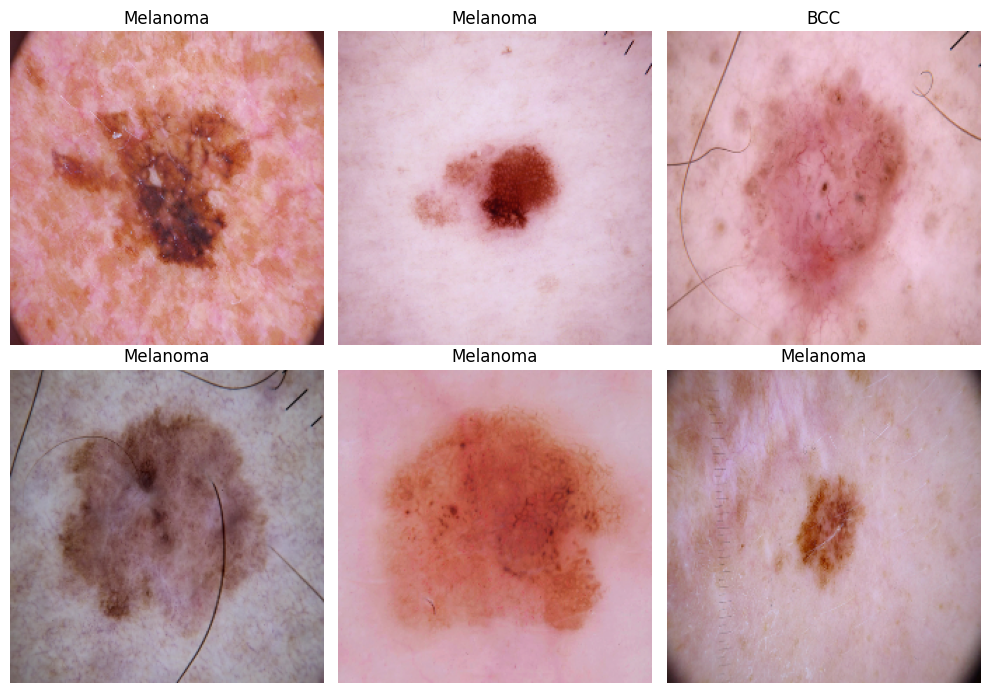

In [6]:
# Copy only training and validation images; test images are not loaded.
for split, frame in [('train', train_frame), ('validation', val_frame)]:
    local_paths = []
    for position, row in enumerate(frame.itertuples(index=False)):
        source = Path(row.image_path)
        if not source.is_file():
            raise FileNotFoundError(source)
        if source.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.bmp'}:
            raise ValueError(f'Unsupported training image format: {source}')
        key = hashlib.sha256(str(source).encode()).hexdigest()
        destination = LOCAL_ROOT / (key + source.suffix.lower())
        if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
            temporary = destination.with_suffix(destination.suffix + '.tmp')
            shutil.copyfile(source, temporary)
            temporary.replace(destination)
        local_paths.append(str(destination))
        if (position + 1) % 250 == 0:
            print(f'{split}: {position + 1}/{len(frame)} copied')
    frame['local_path'] = local_paths
    print(f'{split}: local images ready')

def decode_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(tf.cast(image, tf.float32), IMAGE_SIZE, method='bilinear')
    return image, label

def raw_dataset(frame):
    ds = tf.data.Dataset.from_tensor_slices((
        frame['local_path'].to_numpy(dtype=str),
        frame['label_index'].to_numpy(dtype=np.int32),
    ))
    return ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE).cache()

RAW_TRAIN = raw_dataset(train_frame)
RAW_VAL = raw_dataset(val_frame)
# Fully populate caches once, before model training.
for _ in RAW_TRAIN.batch(BATCH_SIZE):
    pass
for _ in RAW_VAL.batch(BATCH_SIZE):
    pass
VAL_LABELS = val_frame['label_index'].to_numpy(dtype=np.int32)
images, labels = next(iter(RAW_TRAIN.batch(6)))
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for axis, image, label in zip(axes.flat, images.numpy(), labels.numpy()):
    axis.imshow(np.clip(image, 0, 255).astype('uint8'))
    axis.set_title(CLASS_NAMES[int(label)])
    axis.axis('off')
plt.tight_layout()
plt.show()

In [7]:
MODEL_SPECS = {
    'MobileNetV2': (tf.keras.applications.MobileNetV2, tf.keras.applications.mobilenet_v2.preprocess_input, 'mobilenet_v2'),
    'EfficientNetB0': (tf.keras.applications.EfficientNetB0, tf.keras.applications.efficientnet.preprocess_input, 'efficientnet_b0'),
    'ResNet50': (tf.keras.applications.ResNet50, tf.keras.applications.resnet50.preprocess_input, 'resnet50'),
}

def model_datasets(name):
    preprocess = MODEL_SPECS[name][1]
    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED),
        tf.keras.layers.RandomRotation(0.05, fill_mode='reflect', seed=SEED + 1),
        tf.keras.layers.RandomZoom(0.10, fill_mode='reflect', seed=SEED + 2),
        tf.keras.layers.RandomBrightness(0.10, value_range=(0, 255), seed=SEED + 3),
    ])
    def prepare_training(images, labels):
        images = augmentation(images, training=True)
        return preprocess(tf.clip_by_value(images, 0.0, 255.0)), labels
    def prepare_validation(images, labels):
        return preprocess(images), labels
    train_ds = RAW_TRAIN.shuffle(len(train_frame), seed=SEED, reshuffle_each_iteration=True)
    train_ds = train_ds.batch(BATCH_SIZE).map(prepare_training, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    val_ds = RAW_VAL.batch(BATCH_SIZE).map(prepare_validation, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    return train_ds, val_ds

def classification_scores(labels, probabilities):
    predicted = probabilities.argmax(axis=1)
    matrix = np.zeros((3, 3), dtype=np.int64)
    np.add.at(matrix, (labels, predicted), 1)
    true_positive = np.diag(matrix).astype(float)
    precision = np.divide(true_positive, matrix.sum(axis=0), out=np.zeros(3), where=matrix.sum(axis=0) != 0)
    recall = np.divide(true_positive, matrix.sum(axis=1), out=np.zeros(3), where=matrix.sum(axis=1) != 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(3), where=(precision + recall) != 0)
    return float(f1.mean()), float((labels == predicted).mean())

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    )

class ValidationCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, name, val_ds, model_dir, report_dir):
        super().__init__()
        self.name = name
        self.val_ds = val_ds
        self.model_dir = model_dir
        self.report_dir = report_dir
        self.best = -1.0
        self.best_accuracy = None
        self.best_phase = None
        self.best_epoch = None
        self.phase = 'head'
        self.rows = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        probabilities = self.model.predict(self.val_ds, verbose=0)
        macro_f1, accuracy = classification_scores(VAL_LABELS, probabilities)
        logs['val_macro_f1'] = macro_f1
        self.rows.append({'phase': self.phase, 'epoch': epoch + 1, **{key: float(value) for key, value in logs.items()}})
        pd.DataFrame(self.rows).to_csv(self.report_dir / 'training_history.csv', index=False)
        print(f' — validation macro F1: {macro_f1:.4f}')
        if macro_f1 > self.best:
            self.best = macro_f1
            self.best_accuracy = accuracy
            self.best_phase = self.phase
            self.best_epoch = epoch + 1
            self.model.save(self.model_dir / 'best.keras')
            self.model.save_weights(self.model_dir / 'best.weights.h5')
            write_json(self.model_dir / 'checkpoint.json', {
                'validation_macro_f1': macro_f1, 'validation_accuracy': accuracy,
                'phase': self.phase, 'epoch': epoch + 1, 'class_names': CLASS_NAMES,
            })
            print('Best checkpoint saved to Drive.')

def stop_callback():
    return tf.keras.callbacks.EarlyStopping(monitor='val_macro_f1', mode='max', patience=3, restore_best_weights=False)

def train_one_model(name):
    model_dir = RUN_MODELS / name
    report_dir = RUN_REPORTS / name
    model_dir.mkdir(parents=True, exist_ok=True)
    report_dir.mkdir(parents=True, exist_ok=True)
    metadata_path = model_dir / 'metadata.json'
    if metadata_path.is_file():
        saved = json.loads(metadata_path.read_text())
        if saved.get('training_complete') and saved.get('run_id') == RUN_ID and (model_dir / 'best.keras').is_file():
            print(name, 'already complete for this run; skipping.')
            return saved
    # Never overwrite an incomplete attempt: retain its checkpoints/history.
    if (model_dir / 'best.keras').exists() or (report_dir / 'training_history.csv').exists():
        stamp = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
        model_dir.rename(RUN_MODELS / f'{name}_interrupted_{stamp}')
        report_dir.rename(RUN_REPORTS / f'{name}_interrupted_{stamp}')
        model_dir.mkdir()
        report_dir.mkdir()

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    train_ds, val_ds = model_datasets(name)
    constructor, _, preprocess_name = MODEL_SPECS[name]
    base = constructor(weights='imagenet', include_top=False, input_shape=(*IMAGE_SIZE, 3))
    base.trainable = False
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3), name='preprocessed_image')
    features = base(inputs, training=False)
    features = tf.keras.layers.GlobalAveragePooling2D()(features)
    features = tf.keras.layers.Dropout(0.30, seed=SEED)(features)
    outputs = tf.keras.layers.Dense(3, activation='softmax', name='class_scores')(features)
    model = tf.keras.Model(inputs, outputs, name=name + '_skin_classifier')
    monitor = ValidationCheckpoint(name, val_ds, model_dir, report_dir)
    started = time.time()

    print('\nTRAINING CLASSIFICATION HEAD:', name)
    compile_model(model, 0.001)
    model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
              class_weight=CLASS_WEIGHTS, callbacks=[monitor, stop_callback()], verbose=2)
    model.load_weights(model_dir / 'best.weights.h5')

    print('\nFINE-TUNING:', name)
    base.trainable = True
    cutoff = int(len(base.layers) * 0.80)
    for index, layer in enumerate(base.layers):
        layer.trainable = index >= cutoff and not isinstance(layer, tf.keras.layers.BatchNormalization)
    compile_model(model, 0.00001)
    monitor.phase = 'fine_tune'
    model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
              class_weight=CLASS_WEIGHTS, callbacks=[monitor, stop_callback()], verbose=2)

    # Validate serialization: loaded best model must reproduce its weights.
    model.load_weights(model_dir / 'best.weights.h5')
    reference_batch, _ = next(iter(val_ds))
    reference_scores = model.predict(reference_batch, verbose=0)
    loaded = tf.keras.models.load_model(model_dir / 'best.keras', compile=False)
    reloaded_scores = loaded.predict(reference_batch, verbose=0)
    np.testing.assert_allclose(reference_scores, reloaded_scores, rtol=1e-4, atol=1e-5)
    np.savez(report_dir / 'validation_reference.npz', scores=reloaded_scores, labels=VAL_LABELS[:len(reloaded_scores)])
    val_frame.head(len(reloaded_scores)).to_csv(report_dir / 'validation_reference_images.csv', index=False)

    metadata = {
        'model_name': name, 'run_id': RUN_ID, 'training_complete': True,
        'model_file': str(model_dir / 'best.keras'),
        'model_sha256': hashlib.sha256((model_dir / 'best.keras').read_bytes()).hexdigest(),
        'class_names': CLASS_NAMES, 'class_to_index': CLASS_TO_INDEX,
        'image_size': list(IMAGE_SIZE), 'color_mode': 'RGB',
        'resize': 'tf.image.resize bilinear; stretch to 224x224',
        'decode': 'tf.io.decode_image channels=3; no EXIF orientation transform',
        'preprocessing': preprocess_name, 'preprocessing_location': 'outside saved model',
        'tensorflow_version': tf.__version__,
        'keras_version': getattr(tf.keras, '__version__', None),
        'manifest_hashes': manifest_hashes, 'class_weights': CLASS_WEIGHTS,
        'selection_metric': 'validation_macro_f1',
        'validation_macro_f1': monitor.best,
        'validation_accuracy': monitor.best_accuracy,
        'best_phase': monitor.best_phase, 'best_epoch': monitor.best_epoch,
        'training_seconds': round(time.time() - started, 2),
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
        'test_set_used_for_training_or_selection': False,
    }
    write_json(metadata_path, metadata)
    history = pd.DataFrame(monitor.rows)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(history['loss'], label='train')
    axes[0].plot(history['val_loss'], label='validation')
    axes[0].set_title('Loss')
    axes[1].plot(history['accuracy'], label='train')
    axes[1].plot(history['val_accuracy'], label='validation')
    axes[1].set_title('Accuracy')
    axes[2].plot(history['val_macro_f1'], label='validation macro F1')
    axes[2].set_title('Validation macro F1')
    for axis in axes:
        axis.set_xlabel('Recorded epoch (head then fine-tuning)')
        axis.legend()
    fig.tight_layout()
    fig.savefig(report_dir / 'training_curves.png', dpi=160)
    plt.close(fig)
    del loaded, model, base, monitor, train_ds, val_ds
    tf.keras.backend.clear_session()
    gc.collect()
    print(name, 'COMPLETE. Best validation macro F1:', metadata['validation_macro_f1'])
    return metadata

In [ ]:
mobilenet_result = train_one_model('MobileNetV2')
display(pd.DataFrame([mobilenet_result])[
    ['model_name', 'validation_macro_f1', 'validation_accuracy', 'best_phase', 'training_seconds']
])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

TRAINING CLASSIFICATION HEAD: MobileNetV2
Epoch 1/6
 — validation macro F1: 0.5773
Best checkpoint saved to Drive.
120/120 - 53s - 441ms/step - accuracy: 0.5675 - loss: 0.9764 - val_accuracy: 0.6667 - val_loss: 0.6676 - val_macro_f1: 0.5773
Epoch 2/6
 — validation macro F1: 0.6384
Best checkpoint saved to Drive.
120/120 - 22s - 181ms/step - accuracy: 0.6441 - loss: 0.7213 - val_accuracy: 0.7846 - val_loss: 0.4823 - val_macro_f1: 0.6384
Epoch 3/6
 — validation macro F1: 0.6252
120/120 - 21s - 173ms/step - accuracy: 0.6924 - loss: 0.6602 - val_accuracy: 0.7744 - val_loss: 0.5026 - val_macro_f1: 0.6252
Epoch 4/6
 — validation macro F1: 0.6217
120/120 - 41s - 339ms/step - accuracy: 0.7134 - loss: 0.5987 - val_accuracy: 0.8205 - val_loss: 0.4631 - val_macro_f1: 0.6217
Epoch 5/6
 — validation macro F1: 0.5860
120/120 - 41s - 343ms/step - accuracy: 0.7297 - loss: 0.6164 - val_accuracy: 0.7000 - val_loss: 0.5884 - val_macro_f1: 0.5860

FINE-TUN

,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
0,MobileNetV2,0.660937,0.792308,fine_tune,355.05


In [ ]:
efficientnet_result = train_one_model('EfficientNetB0')
display(pd.DataFrame([efficientnet_result])[
    ['model_name', 'validation_macro_f1', 'validation_accuracy', 'best_phase', 'training_seconds']
])

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

TRAINING CLASSIFICATION HEAD: EfficientNetB0
Epoch 1/6
 — validation macro F1: 0.4603
Best checkpoint saved to Drive.
120/120 - 90s - 753ms/step - accuracy: 0.5444 - loss: 0.8771 - val_accuracy: 0.5410 - val_loss: 0.7986 - val_macro_f1: 0.4603
Epoch 2/6
 — validation macro F1: 0.5666
Best checkpoint saved to Drive.
120/120 - 26s - 220ms/step - accuracy: 0.6262 - loss: 0.6988 - val_accuracy: 0.6564 - val_loss: 0.6156 - val_macro_f1: 0.5666
Epoch 3/6
 — validation macro F1: 0.5713
Best checkpoint saved to Drive.
120/120 - 26s - 213ms/step - accuracy: 0.6651 - loss: 0.6444 - val_accuracy: 0.6513 - val_loss: 0.6257 - val_macro_f1: 0.5713
Epoch 4/6
 — validation macro F1: 0.6401
Best checkpoint saved to Drive.
120/120 - 26s - 213ms/step - accuracy: 0.7003 - loss: 0.5987 - val_accuracy: 0.7564 - val_loss: 0.5389 - val_macro_f1: 0.6401
Epoch 5/6
 — validation macro F1: 0.6150
120/120 - 23s - 191ms/step - accuracy: 0.6866 - loss: 0.5938 - val

,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
0,EfficientNetB0,0.662763,0.774359,fine_tune,528.66


In [ ]:
resnet_result = train_one_model('ResNet50')
display(pd.DataFrame([resnet_result])[
    ['model_name', 'validation_macro_f1', 'validation_accuracy', 'best_phase', 'training_seconds']
])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

TRAINING CLASSIFICATION HEAD: ResNet50
Epoch 1/6
 — validation macro F1: 0.5577
Best checkpoint saved to Drive.
120/120 - 63s - 524ms/step - accuracy: 0.5990 - loss: 0.9325 - val_accuracy: 0.6256 - val_loss: 0.8717 - val_macro_f1: 0.5577
Epoch 2/6
 — validation macro F1: 0.6261
Best checkpoint saved to Drive.
120/120 - 36s - 297ms/step - accuracy: 0.6997 - loss: 0.6815 - val_accuracy: 0.7385 - val_loss: 0.5822 - val_macro_f1: 0.6261
Epoch 3/6
 — validation macro F1: 0.6056
120/120 - 27s - 224ms/step - accuracy: 0.7312 - loss: 0.6013 - val_accuracy: 0.7333 - val_loss: 0.6254 - val_macro_f1: 0.6056
Epoch 4/6
 — validation macro F1: 0.6265
Best checkpoint saved to Drive.
120/120 - 31s - 257ms/step - accuracy: 0.7507 - loss: 0.5693 - val_accuracy: 0.7718 - val_loss: 0.5099 - val_macro_f1: 0.6265
Epoch 5/6
 — validation macro F1: 0.5767
120/120 - 27s - 228ms/step - accuracy: 0.7428 - loss: 0.5841 - val_accuracy: 0.6692 - val_loss: 0.7931 -

,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
0,ResNet50,0.658761,0.820513,fine_tune,488.83


In [ ]:
results = []
for name in MODEL_SPECS:
    metadata_path = RUN_MODELS / name / 'metadata.json'
    if not metadata_path.is_file():
        raise FileNotFoundError(f'Finish training {name} first.')
    result = json.loads(metadata_path.read_text())
    if not result.get('training_complete') or result['run_id'] != RUN_ID:
        raise ValueError(f'{name}: training is incomplete or belongs to another run.')
    results.append(result)
comparison = pd.DataFrame([
    {key: row[key] for key in ['model_name', 'validation_macro_f1', 'validation_accuracy', 'best_phase', 'training_seconds']}
    for row in results
]).sort_values(['validation_macro_f1', 'model_name'], ascending=[False, True])
comparison.to_csv(RUN_REPORTS / 'validation_model_comparison.csv', index=False)
display(comparison)
selected_name = comparison.iloc[0]['model_name']
selected = next(row for row in results if row['model_name'] == selected_name)
EXPORT_ROOT = PROJECT_ROOT / 'Models' / 'Selected' / RUN_ID
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)
shutil.copyfile(selected['model_file'], EXPORT_ROOT / 'model.keras')
export_metadata = {**selected, 'model_file': str(EXPORT_ROOT / 'model.keras')}
write_json(EXPORT_ROOT / 'metadata.json', export_metadata)
write_json(EXPORT_ROOT / 'class_names.json', CLASS_NAMES)
write_json(MODEL_ROOT / 'latest_completed_run.json', {
    'run_id': RUN_ID, 'models_directory': str(RUN_MODELS),
    'reports_directory': str(RUN_REPORTS), 'selected_model': selected_name,
    'selected_directory': str(EXPORT_ROOT),
})
print('MODEL TRAINING COMPLETE')
print('Selected using validation macro F1:', selected_name)
print('Selected model folder:', EXPORT_ROOT)
print('Test evaluation has NOT been performed yet. Continue in notebook 6.')

,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
1,EfficientNetB0,0.662763,0.774359,fine_tune,528.66
0,MobileNetV2,0.660937,0.792308,fine_tune,355.05
2,ResNet50,0.658761,0.820513,fine_tune,488.83


MODEL TRAINING COMPLETE
Selected using validation macro F1: EfficientNetB0
Selected model folder: /content/drive/MyDrive/cnn-skin-cancer-classification/Models/Selected/77751764c605
Test evaluation has NOT been performed yet. Continue in notebook 6.


## Training interpretation and limitations

Model selection uses validation macro F1. Reported validation accuracy is not final test accuracy. The test set has not been used to tune or select models.

Class imbalance and the relationship between image source and class remain limitations. SCC appears only in the PAD-UFES-20 selection. HAM patient-level separation cannot be verified because patient identifiers are unavailable.

The selected model produces scores for three cancer classes; it has no benign/no-cancer class. Outputs are research decision-support results rather than clinical diagnoses.

## Experiment 2 — revised classification head and deeper fine-tuning

Experiment 1 selected EfficientNetB0 using validation macro F1. Its test accuracy was 81.13% and test macro F1 was 0.7054, below the required ≥85% accuracy and >0.80 macro F1. SCC was the weakest class.

Experiment 2 adds a Dense ReLU head, increases maximum training duration, unfreezes more backbone layers while keeping batch normalization frozen, and reduces the learning rate when validation macro F1 stalls. Training-only class weights and augmentation are retained.

All models start from ImageNet weights and use the same group-separated splits. Checkpoint and candidate selection use validation macro F1 only. Per-class validation metrics and errors are recorded to examine SCC performance.

The original test results have already been inspected and motivated this experiment. Any subsequent evaluation on that same test set is a follow-up evaluation, not a fresh independent final test. New independent held-out data would be needed for a fresh estimate.

In [ ]:
# Requires the original setup cells 2–5 to have run in this runtime.
BASELINE_RUN_ID = '77751764c605'
BASELINE_MODELS = MODEL_ROOT / BASELINE_RUN_ID
baseline_results = []
for name in MODEL_SPECS:
    path = BASELINE_MODELS / name / 'metadata.json'
    info = json.loads(path.read_text())
    if not info.get('training_complete'):
        raise ValueError(f'{name}: baseline training is incomplete.')
    if info['manifest_hashes'] != manifest_hashes:
        raise ValueError('Splits differ from Experiment 1. Do not continue.')
    baseline_results.append(info)

HEAD_EPOCHS = 12
FINE_TUNE_EPOCHS = 25
EXPERIMENT_SETTINGS = {
    **SETTINGS,
    'experiment': 'experiment_02',
    'baseline_run_id': BASELINE_RUN_ID,
    'head_epochs': HEAD_EPOCHS,
    'fine_tune_epochs': FINE_TUNE_EPOCHS,
    'head_dense_units': 128,
    'head_dense_activation': 'relu',
    'dropout': 0.30,
    'fine_tune_fraction': 0.50,
    'early_stopping_patience': 6,
    'reduce_lr_patience': 3,
    'reduce_lr_factor': 0.5,
    'test_results_already_inspected': True,
}
RUN_ID = 'exp02_' + hashlib.sha256(
    json.dumps(EXPERIMENT_SETTINGS, sort_keys=True).encode()
).hexdigest()[:12]
RUN_MODELS = MODEL_ROOT / RUN_ID
RUN_REPORTS = REPORT_ROOT / RUN_ID
RUN_MODELS.mkdir(parents=True, exist_ok=True)
RUN_REPORTS.mkdir(parents=True, exist_ok=True)
write_json(RUN_REPORTS / 'training_settings.json', EXPERIMENT_SETTINGS)
print('EXPERIMENT 2:', RUN_ID)
print('Models:', RUN_MODELS)
print('Reports:', RUN_REPORTS)
print('Training/validation records:', len(train_frame), len(val_frame))
print('Class weights:', CLASS_WEIGHTS)
print('Test images will not be loaded or predicted here.')

EXPERIMENT 2: exp02_65b8c20800f3
Models: /content/drive/MyDrive/cnn-skin-cancer-classification/Models/Transfer_Learning/exp02_65b8c20800f3
Reports: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/Training/exp02_65b8c20800f3
Training/validation records: 1905 390
Class weights: {0: 0.6642259414225942, 1: 0.7753357753357754, 2: 4.884615384615385}
Test images will not be loaded or predicted here.


In [ ]:
def reduce_lr_callback():
    return tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_macro_f1', mode='max', factor=0.5,
        patience=3, min_lr=1e-7, verbose=1,
    )

def stop_callback():
    return tf.keras.callbacks.EarlyStopping(monitor='val_macro_f1', mode='max', patience=6, restore_best_weights=False)

def train_one_model(name):
    model_dir = RUN_MODELS / name
    report_dir = RUN_REPORTS / name
    model_dir.mkdir(parents=True, exist_ok=True)
    report_dir.mkdir(parents=True, exist_ok=True)
    metadata_path = model_dir / 'metadata.json'
    if metadata_path.is_file():
        saved = json.loads(metadata_path.read_text())
        if saved.get('training_complete') and saved.get('run_id') == RUN_ID and (model_dir / 'best.keras').is_file():
            print(name, 'already complete for this run; skipping.')
            return saved
    # Never overwrite an incomplete attempt: retain its checkpoints/history.
    if (model_dir / 'best.keras').exists() or (report_dir / 'training_history.csv').exists():
        stamp = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
        model_dir.rename(RUN_MODELS / f'{name}_interrupted_{stamp}')
        report_dir.rename(RUN_REPORTS / f'{name}_interrupted_{stamp}')
        model_dir.mkdir()
        report_dir.mkdir()

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    train_ds, val_ds = model_datasets(name)
    constructor, _, preprocess_name = MODEL_SPECS[name]
    base = constructor(weights='imagenet', include_top=False, input_shape=(*IMAGE_SIZE, 3))
    base.trainable = False
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3), name='preprocessed_image')
    features = base(inputs, training=False)
    features = tf.keras.layers.GlobalAveragePooling2D()(features)
    features = tf.keras.layers.Dense(128, activation='relu', name='research_head')(features)
    features = tf.keras.layers.Dropout(0.30, seed=SEED)(features)
    outputs = tf.keras.layers.Dense(3, activation='softmax', name='class_scores')(features)
    model = tf.keras.Model(inputs, outputs, name=name + '_skin_classifier')
    monitor = ValidationCheckpoint(name, val_ds, model_dir, report_dir)
    started = time.time()

    print('\nTRAINING CLASSIFICATION HEAD:', name)
    compile_model(model, 0.001)
    model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
              class_weight=CLASS_WEIGHTS, callbacks=[monitor, reduce_lr_callback(), stop_callback()], verbose=2)
    model.load_weights(model_dir / 'best.weights.h5')

    print('\nFINE-TUNING:', name)
    base.trainable = True
    cutoff = int(len(base.layers) * 0.50)
    for index, layer in enumerate(base.layers):
        layer.trainable = index >= cutoff and not isinstance(layer, tf.keras.layers.BatchNormalization)
    compile_model(model, 0.00001)
    monitor.phase = 'fine_tune'
    model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
              class_weight=CLASS_WEIGHTS, callbacks=[monitor, reduce_lr_callback(), stop_callback()], verbose=2)

    # Validate serialization: loaded best model must reproduce its weights.
    model.load_weights(model_dir / 'best.weights.h5')
    reference_batch, _ = next(iter(val_ds))
    reference_scores = model.predict(reference_batch, verbose=0)
    loaded = tf.keras.models.load_model(model_dir / 'best.keras', compile=False)
    reloaded_scores = loaded.predict(reference_batch, verbose=0)
    np.testing.assert_allclose(reference_scores, reloaded_scores, rtol=1e-4, atol=1e-5)
    np.savez(report_dir / 'validation_reference.npz', scores=reloaded_scores, labels=VAL_LABELS[:len(reloaded_scores)])
    val_frame.head(len(reloaded_scores)).to_csv(report_dir / 'validation_reference_images.csv', index=False)

    # Full validation diagnostics for the saved best checkpoint.
    from sklearn.metrics import classification_report, confusion_matrix
    validation_scores = loaded.predict(val_ds, verbose=0)
    predicted = validation_scores.argmax(axis=1)
    report = classification_report(
        VAL_LABELS, predicted, labels=[0, 1, 2],
        target_names=CLASS_NAMES, output_dict=True, zero_division=0,
    )
    class_report = pd.DataFrame([
        {'class_label': label, **report[label]} for label in CLASS_NAMES
    ])
    class_report.to_csv(report_dir / 'validation_per_class_metrics.csv', index=False)
    display(class_report)
    pd.DataFrame(confusion_matrix(VAL_LABELS, predicted, labels=[0, 1, 2]),
                 index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        report_dir / 'validation_confusion_matrix.csv')
    predictions = val_frame.drop(columns=['local_path'], errors='ignore').copy()
    predictions['predicted_class'] = [CLASS_NAMES[i] for i in predicted]
    for index, label in enumerate(CLASS_NAMES):
        predictions[f'score_{label}'] = validation_scores[:, index]
    predictions.to_csv(report_dir / 'validation_predictions.csv', index=False)
    predictions.loc[predictions['class_label'] != predictions['predicted_class']].to_csv(
        report_dir / 'validation_errors.csv', index=False)
    best_f1, best_accuracy = classification_scores(VAL_LABELS, validation_scores)
    np.testing.assert_allclose(best_f1, monitor.best, atol=1e-8)
    np.testing.assert_allclose(best_accuracy, monitor.best_accuracy, atol=1e-8)

    metadata = {
        'model_name': name, 'run_id': RUN_ID, 'training_complete': True,
        'model_file': str(model_dir / 'best.keras'),
        'model_sha256': hashlib.sha256((model_dir / 'best.keras').read_bytes()).hexdigest(),
        'class_names': CLASS_NAMES, 'class_to_index': CLASS_TO_INDEX,
        'image_size': list(IMAGE_SIZE), 'color_mode': 'RGB',
        'resize': 'tf.image.resize bilinear; stretch to 224x224',
        'decode': 'tf.io.decode_image channels=3; no EXIF orientation transform',
        'preprocessing': preprocess_name, 'preprocessing_location': 'outside saved model',
        'tensorflow_version': tf.__version__,
        'keras_version': getattr(tf.keras, '__version__', None),
        'manifest_hashes': manifest_hashes, 'class_weights': CLASS_WEIGHTS,
        'selection_metric': 'validation_macro_f1',
        'validation_macro_f1': monitor.best,
        'validation_accuracy': monitor.best_accuracy,
        'best_phase': monitor.best_phase, 'best_epoch': monitor.best_epoch,
        'training_seconds': round(time.time() - started, 2),
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
        'experiment': 'experiment_02',
        'experiment_settings': EXPERIMENT_SETTINGS,
        'original_test_results_already_inspected': True,
        'test_images_used_for_gradient_updates': False,
        'checkpoint_selection_uses_validation_only': True,
    }
    write_json(metadata_path, metadata)
    history = pd.DataFrame(monitor.rows)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(history['loss'], label='train')
    axes[0].plot(history['val_loss'], label='validation')
    axes[0].set_title('Loss')
    axes[1].plot(history['accuracy'], label='train')
    axes[1].plot(history['val_accuracy'], label='validation')
    axes[1].set_title('Accuracy')
    axes[2].plot(history['val_macro_f1'], label='validation macro F1')
    axes[2].set_title('Validation macro F1')
    for axis in axes:
        axis.set_xlabel('Recorded epoch (head then fine-tuning)')
        axis.legend()
    fig.tight_layout()
    fig.savefig(report_dir / 'training_curves.png', dpi=160)
    plt.close(fig)
    del loaded, model, base, monitor, train_ds, val_ds
    tf.keras.backend.clear_session()
    gc.collect()
    print(name, 'COMPLETE. Best validation macro F1:', metadata['validation_macro_f1'])
    return metadata

In [ ]:
result = train_one_model('MobileNetV2')
display(pd.DataFrame([result])[[
    'model_name', 'validation_macro_f1', 'validation_accuracy',
    'best_phase', 'training_seconds',
]])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

TRAINING CLASSIFICATION HEAD: MobileNetV2
Epoch 1/12
 — validation macro F1: 0.5474
Best checkpoint saved to Drive.
120/120 - 58s - 481ms/step - accuracy: 0.6425 - loss: 0.8731 - val_accuracy: 0.6103 - val_loss: 0.7673 - val_macro_f1: 0.5474 - learning_rate: 0.0010
Epoch 2/12
 — validation macro F1: 0.6110
Best checkpoint saved to Drive.
120/120 - 26s - 214ms/step - accuracy: 0.6903 - loss: 0.6352 - val_accuracy: 0.7051 - val_loss: 0.5789 - val_macro_f1: 0.6110 - learning_rate: 0.0010
Epoch 3/12
 — validation macro F1: 0.5998
120/120 - 38s - 318ms/step - accuracy: 0.7543 - loss: 0.5456 - val_accuracy: 0.7538 - val_loss: 0.4959 - val_macro_f1: 0.5998 - learning_rate: 0.0010
Epoch 4/12
 — validation macro F1: 0.6449
Best checkpoint saved to Drive.
120/120 - 23s - 191ms/step - accuracy: 0.7375 - loss: 0.5216 - val_accuracy: 0.7744 - val_loss: 0.4952 - val_macro_f1: 0.6449 - learning_rate: 0.0010
Epoch 5/12
 — validation macro F1: 0.6174
12

,class_label,precision,recall,f1-score,support
0,BCC,0.867925,0.690000,0.768802,200.0
1,Melanoma,0.854839,0.969512,0.908571,164.0
2,SCC,0.222222,0.384615,0.281690,26.0


MobileNetV2 COMPLETE. Best validation macro F1: 0.6530212659429183


,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
0,MobileNetV2,0.653021,0.787179,fine_tune,573.37


In [ ]:
result = train_one_model('EfficientNetB0')
display(pd.DataFrame([result])[[
    'model_name', 'validation_macro_f1', 'validation_accuracy',
    'best_phase', 'training_seconds',
]])

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

TRAINING CLASSIFICATION HEAD: EfficientNetB0
Epoch 1/12
 — validation macro F1: 0.5536
Best checkpoint saved to Drive.
120/120 - 95s - 794ms/step - accuracy: 0.6063 - loss: 0.7713 - val_accuracy: 0.6154 - val_loss: 0.7169 - val_macro_f1: 0.5536 - learning_rate: 0.0010
Epoch 2/12
 — validation macro F1: 0.6124
Best checkpoint saved to Drive.
120/120 - 24s - 200ms/step - accuracy: 0.6730 - loss: 0.6159 - val_accuracy: 0.7359 - val_loss: 0.5258 - val_macro_f1: 0.6124 - learning_rate: 0.0010
Epoch 3/12
 — validation macro F1: 0.6305
Best checkpoint saved to Drive.
120/120 - 26s - 214ms/step - accuracy: 0.7197 - loss: 0.5601 - val_accuracy: 0.7282 - val_loss: 0.5676 - val_macro_f1: 0.6305 - learning_rate: 0.0010
Epoch 4/12
 — validation macro F1: 0.6158
120/120 - 23s - 189ms/step - accuracy: 0.7192 - loss: 0.5357 - val_accuracy: 0.7487 - val_loss: 0.5071 - val_macro_f1: 0.6158 - learning_rate: 0.0010
Epoch 5/12
 — validation macro F1: 0.63

,class_label,precision,recall,f1-score,support
0,BCC,0.876344,0.815000,0.844560,200.0
1,Melanoma,0.881356,0.951220,0.914956,164.0
2,SCC,0.296296,0.307692,0.301887,26.0


EfficientNetB0 COMPLETE. Best validation macro F1: 0.6871341298917545


,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
0,EfficientNetB0,0.687134,0.838462,fine_tune,1135.03


In [ ]:
result = train_one_model('ResNet50')
display(pd.DataFrame([result])[[
    'model_name', 'validation_macro_f1', 'validation_accuracy',
    'best_phase', 'training_seconds',
]])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step

TRAINING CLASSIFICATION HEAD: ResNet50
Epoch 1/12
 — validation macro F1: 0.5041
Best checkpoint saved to Drive.
120/120 - 67s - 558ms/step - accuracy: 0.6210 - loss: 0.8883 - val_accuracy: 0.5846 - val_loss: 0.6520 - val_macro_f1: 0.5041 - learning_rate: 0.0010
Epoch 2/12
 — validation macro F1: 0.6306
Best checkpoint saved to Drive.
120/120 - 36s - 300ms/step - accuracy: 0.6861 - loss: 0.5923 - val_accuracy: 0.7436 - val_loss: 0.5009 - val_macro_f1: 0.6306 - learning_rate: 0.0010
Epoch 3/12
 — validation macro F1: 0.5710
120/120 - 34s - 281ms/step - accuracy: 0.7302 - loss: 0.5295 - val_accuracy: 0.6615 - val_loss: 0.5809 - val_macro_f1: 0.5710 - learning_rate: 0.0010
Epoch 4/12
 — validation macro F1: 0.6435
Best checkpoint saved to Drive.
120/120 - 34s - 280ms/step - accuracy: 0.7412 - loss: 0.4971 - val_accuracy: 0.7744 - val_loss: 0.4472 - val_macro_f1: 0.6435 - learning_rate: 0.0010
Epoch 5/12
 — validation macro F1: 0.6146
120

,class_label,precision,recall,f1-score,support
0,BCC,0.879581,0.840000,0.859335,200.0
1,Melanoma,0.957317,0.957317,0.957317,164.0
2,SCC,0.228571,0.307692,0.262295,26.0


ResNet50 COMPLETE. Best validation macro F1: 0.6929823978337054


,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
0,ResNet50,0.692982,0.853846,fine_tune,1130.77


In [ ]:
experiment2_results = []
for name in MODEL_SPECS:
    result = json.loads((RUN_MODELS / name / 'metadata.json').read_text())
    if not result.get('training_complete') or result['run_id'] != RUN_ID:
        raise ValueError(f'Finish Experiment 2 training for {name}.')
    experiment2_results.append(result)

rows = []
for experiment, results in [('Experiment 1', baseline_results),
                            ('Experiment 2', experiment2_results)]:
    for result in results:
        rows.append({
            'experiment': experiment,
            **{key: result[key] for key in [
                'model_name', 'run_id', 'validation_macro_f1',
                'validation_accuracy', 'best_phase', 'training_seconds']},
        })
comparison = pd.DataFrame(rows).sort_values(
    ['validation_macro_f1', 'experiment', 'model_name'],
    ascending=[False, True, True],
).reset_index(drop=True)
comparison.to_csv(RUN_REPORTS / 'experiments_validation_comparison.csv', index=False)
display(comparison)

baseline_scores = {r['model_name']: r['validation_macro_f1'] for r in baseline_results}
deltas = pd.DataFrame([{
    'model_name': r['model_name'],
    'experiment_1_validation_macro_f1': baseline_scores[r['model_name']],
    'experiment_2_validation_macro_f1': r['validation_macro_f1'],
    'change': r['validation_macro_f1'] - baseline_scores[r['model_name']],
} for r in experiment2_results])
deltas.to_csv(RUN_REPORTS / 'validation_improvement.csv', index=False)
display(deltas)

# Compare all six checkpoints using validation only. Ties favour baseline.
winner_row = comparison.iloc[0]
all_results = baseline_results + experiment2_results
winner = next(r for r in all_results if r['run_id'] == winner_row['run_id']
              and r['model_name'] == winner_row['model_name'])
winner_source = Path(winner['model_file'])
if hashlib.sha256(winner_source.read_bytes()).hexdigest() != winner['model_sha256']:
    raise ValueError('Winning model checksum differs from its metadata.')
candidate = PROJECT_ROOT / 'Models' / 'Selected' / RUN_ID
candidate.mkdir(parents=True, exist_ok=True)
shutil.copy2(winner_source, candidate / 'model.keras')
package_metadata = {
    **winner,
    'model_file': str(candidate / 'model.keras'),
    'comparison_run_id': RUN_ID,
    'selected_experiment': winner_row['experiment'],
    'original_test_results_already_inspected': True,
    'checkpoint_selection_uses_validation_only': True,
}
write_json(candidate / 'metadata.json', package_metadata)
write_json(candidate / 'class_names.json', CLASS_NAMES)
write_json(RUN_REPORTS / 'selected_candidate.json', package_metadata)
print('EXPERIMENT 2 TRAINING COMPLETE')
print('Validation winner:', winner_row['experiment'], winner['model_name'])
print('Winning validation macro F1:', winner['validation_macro_f1'])
print('Candidate package:', candidate)
print('Experiment 1 selected package and latest-run pointer were preserved.')
print('Test requirements have NOT been verified for new checkpoints.')

,experiment,model_name,run_id,validation_macro_f1,validation_accuracy,best_phase,training_seconds
0,Experiment 2,ResNet50,exp02_65b8c20800f3,0.692982,0.853846,fine_tune,1130.77
1,Experiment 2,EfficientNetB0,exp02_65b8c20800f3,0.687134,0.838462,fine_tune,1135.03
2,Experiment 1,EfficientNetB0,77751764c605,0.662763,0.774359,fine_tune,528.66
3,Experiment 1,MobileNetV2,77751764c605,0.660937,0.792308,fine_tune,355.05
4,Experiment 1,ResNet50,77751764c605,0.658761,0.820513,fine_tune,488.83
5,Experiment 2,MobileNetV2,exp02_65b8c20800f3,0.653021,0.787179,fine_tune,573.37


,model_name,experiment_1_validation_macro_f1,experiment_2_validation_macro_f1,change
0,MobileNetV2,0.660937,0.653021,-0.007916
1,EfficientNetB0,0.662763,0.687134,0.024372
2,ResNet50,0.658761,0.692982,0.034222


EXPERIMENT 2 TRAINING COMPLETE
Validation winner: Experiment 2 ResNet50
Winning validation macro F1: 0.6929823978337054
Candidate package: /content/drive/MyDrive/cnn-skin-cancer-classification/Models/Selected/exp02_65b8c20800f3
Experiment 1 selected package and latest-run pointer were preserved.
Test requirements have NOT been verified for new checkpoints.


## Experiment 2 — Results and Discussion

Experiment 2 added a Dense 128-unit ReLU classification layer,
increased maximum training duration, expanded fine-tuning to the
upper 50% of backbone layers, and introduced learning-rate reduction.
The original splits, augmentation and class weights were retained.

### Validation results

| Model | Experiment 1 macro F1 | Experiment 2 macro F1 | Change | Experiment 2 accuracy |
|---|---:|---:|---:|---:|
| MobileNetV2 | 0.660937 | 0.653021 | −0.007916 | 78.72% |
| EfficientNetB0 | 0.662763 | 0.687134 | +0.024372 | 83.85% |
| ResNet50 | 0.658761 | 0.692982 | +0.034222 | 85.38% |

### Why the selected model changed

Experiment 1 selected EfficientNetB0 because it achieved the highest
validation macro F1 (0.662763), despite ResNet50 having higher accuracy.
Macro F1 was the selection metric because it gives BCC, Melanoma and
SCC equal importance despite their different sample sizes.

In Experiment 2, ResNet50 achieved the highest validation macro F1
across both experiments (0.692982), exceeding Experiment 2’s
EfficientNetB0 (0.687134). The selection rule remained unchanged;
the revised training configuration changed the model ranking.

ResNet50 is the current candidate for follow-up evaluation.
Its small validation advantage does not establish that it is
consistently superior or that the required test targets have been met.

ResNet50 and EfficientNetB0 improved in validation macro F1,
while MobileNetV2 declined slightly. ResNet50 achieved the
highest validation macro F1 across both experiments and was
selected as the candidate for follow-up evaluation.

All Experiment 2 best checkpoints came from the fine-tuning phase.
Because several settings changed together, the improvements
cannot be attributed to a single change.

### SCC performance

Per-class validation reports were saved for each model.
SCC precision, recall and F1 must be examined separately;
the overall comparison alone does not establish SCC improvement.

### Saved candidate

Selected model: ResNet50  
Run ID: exp02_65b8c20800f3  
Validation accuracy: 85.38%  
Validation macro F1: 0.692982  

Candidate folder:
Models/Selected/exp02_65b8c20800f3

Experiment 1’s model files and results were preserved.

### Requirements and evaluation status

The required test accuracy of at least 85% and test macro F1
above 0.80 have not been verified for this candidate.
Its validation macro F1 also remains below 0.80.

Follow-up evaluation will be performed in notebook 6.
The original test set has already been evaluated, so subsequent
results on it will be reported as follow-up evaluation rather
than a fresh independent final test.

## Experiment 3 — SCC-focused investigation

The objective is to improve validation macro F1 and SCC performance
while preserving the existing group-separated splits.

We first inspect Experiment 2 validation errors. Training changes
will be compared using validation results. Test results will not
be used to choose settings, and no model integration will occur
until the agreed performance requirements are satisfied.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cnn-skin-cancer-classification"
)
EXPERIMENT_2_RUN = "exp02_65b8c20800f3"

TRAINING_REPORTS = (
    PROJECT_ROOT / "Reports" / "Training" / EXPERIMENT_2_RUN
)

MODEL_NAMES = ["MobileNetV2", "EfficientNetB0", "ResNet50"]
CLASS_NAMES = ["BCC", "Melanoma", "SCC"]

summary_rows = []

for model_name in MODEL_NAMES:
    folder = TRAINING_REPORTS / model_name
    metrics_path = folder / "validation_per_class_metrics.csv"
    predictions_path = folder / "validation_predictions.csv"

    for path in [metrics_path, predictions_path]:
        if not path.is_file():
            raise FileNotFoundError(f"Required report missing: {path}")

    metrics = pd.read_csv(metrics_path)
    predictions = pd.read_csv(predictions_path)

    scc_metrics = metrics.loc[
        metrics["class_label"] == "SCC"
    ].iloc[0]

    scc_images = predictions.loc[
        predictions["class_label"] == "SCC"
    ]

    missed_scc = scc_images.loc[
        scc_images["predicted_class"] != "SCC"
    ]

    false_scc = predictions.loc[
        (predictions["class_label"] != "SCC")
        & (predictions["predicted_class"] == "SCC")
    ]

    summary_rows.append({
        "model": model_name,
        "SCC_validation_images": len(scc_images),
        "SCC_precision": scc_metrics["precision"],
        "SCC_recall": scc_metrics["recall"],
        "SCC_F1": scc_metrics["f1-score"],
        "missed_SCC": len(missed_scc),
        "other_images_predicted_as_SCC": len(false_scc),
    })

    print(f"\n{model_name}: actual SCC images predicted as")
    display(
        scc_images["predicted_class"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
        .rename_axis("predicted_class")
        .reset_index(name="image_count")
    )

    print("Actual classes of images incorrectly predicted as SCC")
    display(
        false_scc["class_label"]
        .value_counts()
        .rename_axis("actual_class")
        .reset_index(name="image_count")
    )

print("\nEXPERIMENT 2 — SCC VALIDATION SUMMARY")
scc_summary = pd.DataFrame(summary_rows)
display(scc_summary.round(4))

Mounted at /content/drive

MobileNetV2: actual SCC images predicted as


,predicted_class,image_count
0,BCC,16
1,Melanoma,0
2,SCC,10


Actual classes of images incorrectly predicted as SCC


,actual_class,image_count
0,BCC,35



EfficientNetB0: actual SCC images predicted as


...

,predicted_class,image_count
0,BCC,17
1,Melanoma,1
2,SCC,8


Actual classes of images incorrectly predicted as SCC


,actual_class,image_count
0,BCC,26
1,Melanoma,1



EXPERIMENT 2 — SCC VALIDATION SUMMARY


,model,SCC_validation_images,SCC_precision,SCC_recall,SCC_F1,missed_SCC,other_images_predicted_as_SCC
0,MobileNetV2,26,0.2222,0.3846,0.2817,16,35
1,EfficientNetB0,26,0.2963,0.3077,0.3019,18,19
2,ResNet50,26,0.2286,0.3077,0.2623,18,27


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cnn-skin-cancer-classification"
)

TRAINING_REPORTS = (
    PROJECT_ROOT
    / "Reports"
    / "Training"
    / "exp02_65b8c20800f3"
)

Mounted at /content/drive



Actual SCC — predicted BCC: 17 validation images


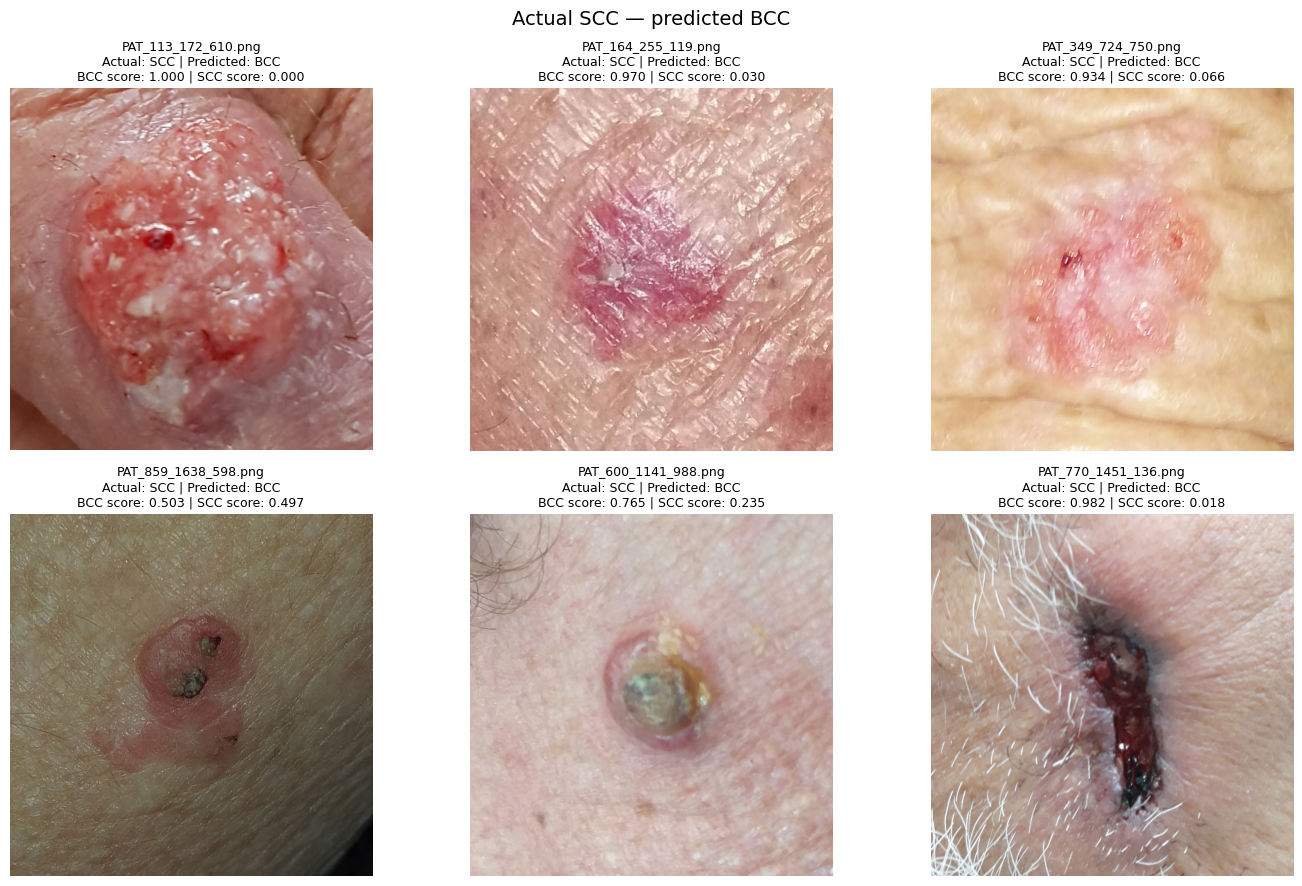


Actual BCC — predicted SCC: 26 validation images


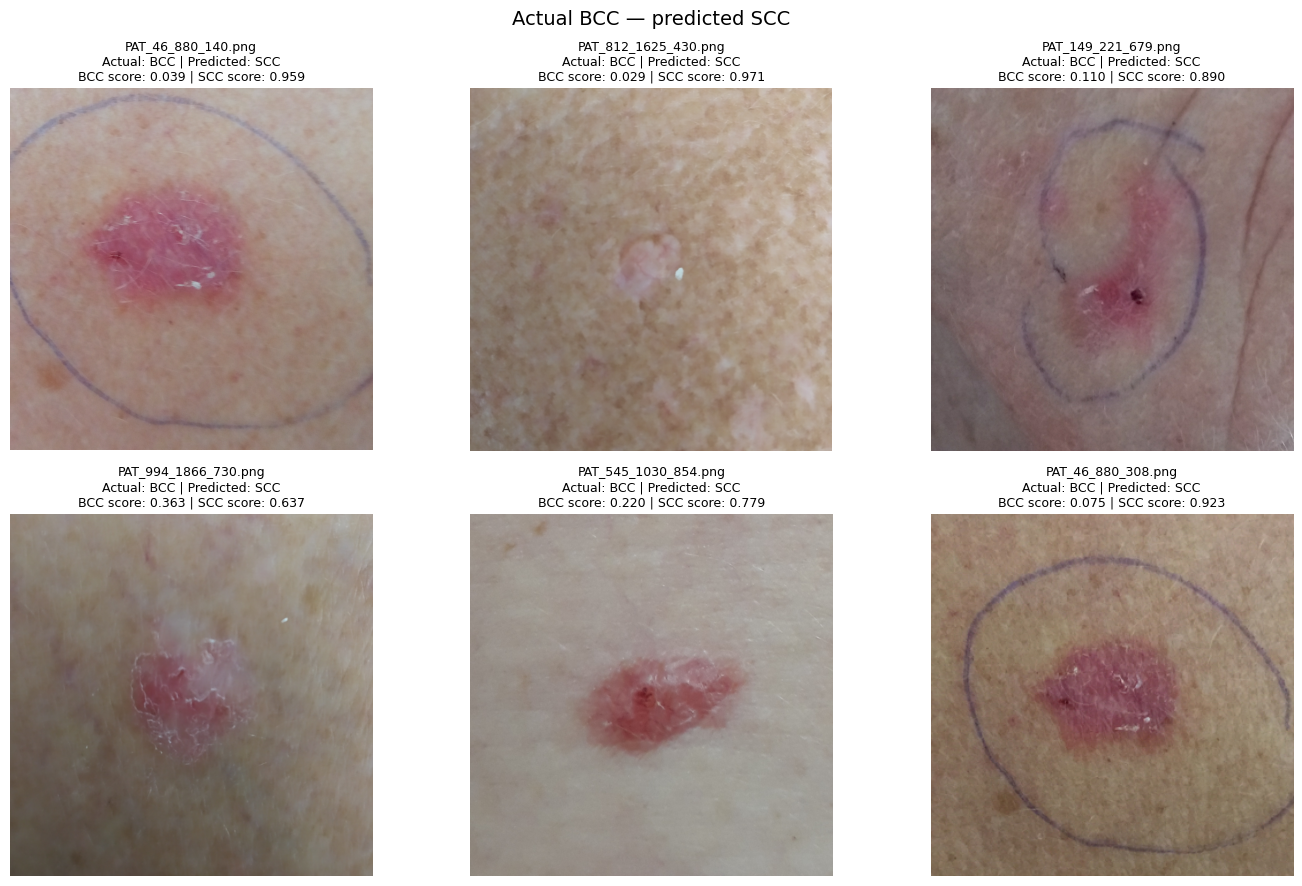


Actual SCC — correctly predicted SCC: 8 validation images


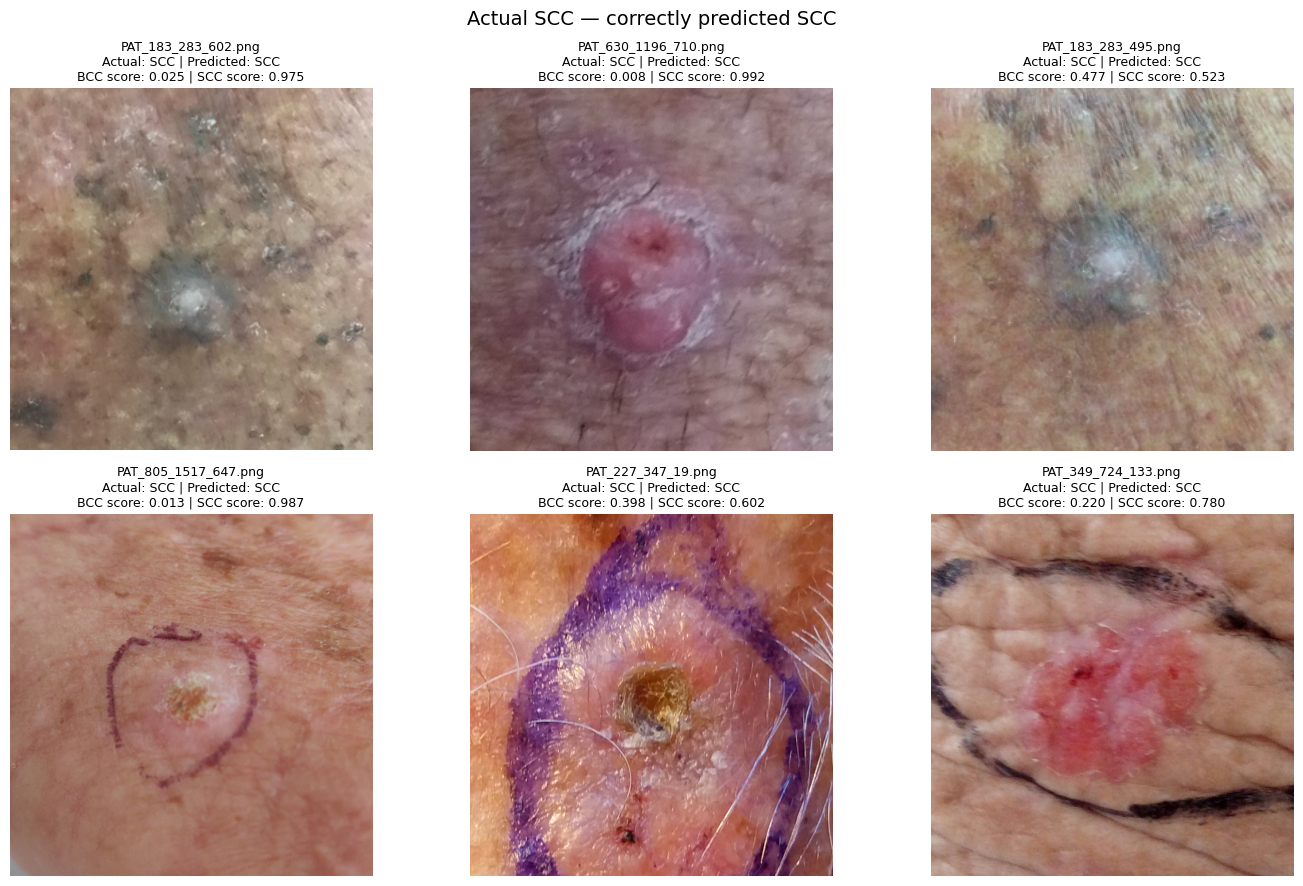

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

predictions = pd.read_csv(
    TRAINING_REPORTS / "ResNet50" / "validation_predictions.csv"
)

groups = {
    "Actual SCC — predicted BCC": predictions.loc[
        (predictions["class_label"] == "SCC")
        & (predictions["predicted_class"] == "BCC")
    ],
    "Actual BCC — predicted SCC": predictions.loc[
        (predictions["class_label"] == "BCC")
        & (predictions["predicted_class"] == "SCC")
    ],
    "Actual SCC — correctly predicted SCC": predictions.loc[
        (predictions["class_label"] == "SCC")
        & (predictions["predicted_class"] == "SCC")
    ],
}

for title, records in groups.items():
    # Fixed sample for reproducible visual inspection.
    examples = records.sample(
        n=min(6, len(records)),
        random_state=42,
    )

    print(f"\n{title}: {len(records)} validation images")

    if examples.empty:
        continue

    fig, axes = plt.subplots(2, 3, figsize=(14, 9))

    for axis in axes.flat:
        axis.axis("off")

    for axis, (_, row) in zip(axes.flat, examples.iterrows()):
        with Image.open(row["image_path"]) as image:
            axis.imshow(image.convert("RGB"))

        axis.set_title(
            f"{row['image_id']}\n"
            f"Actual: {row['class_label']} | "
            f"Predicted: {row['predicted_class']}\n"
            f"BCC score: {row['score_BCC']:.3f} | "
            f"SCC score: {row['score_SCC']:.3f}",
            fontsize=9,
        )

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

In [ ]:
# Experiment 3: balanced training sampling.
# Requires original notebook 5 setup cells 2–5.

import math
import numpy as np
import tensorflow as tf

required_variables = [
    "train_frame", "RAW_TRAIN", "RAW_VAL",
    "MODEL_SPECS", "BATCH_SIZE", "SEED", "CLASS_NAMES",
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run original setup cells 2–5 first. Missing: "
        + ", ".join(missing)
    )

if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("Enable the T4 GPU before training.")

TRAIN_STEPS = math.ceil(len(train_frame) / BATCH_SIZE)

def experiment3_datasets(model_name):
    preprocess = MODEL_SPECS[model_name][1]

    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip(
            "horizontal_and_vertical", seed=SEED
        ),
        tf.keras.layers.RandomRotation(
            0.05, fill_mode="reflect", seed=SEED + 1
        ),
        tf.keras.layers.RandomZoom(
            0.10, fill_mode="reflect", seed=SEED + 2
        ),
        tf.keras.layers.RandomBrightness(
            0.10, value_range=(0, 255), seed=SEED + 3
        ),
    ])

    class_streams = []

    for index in range(len(CLASS_NAMES)):
        count = int(
            (train_frame["label_index"] == index).sum()
        )

        if count == 0:
            raise ValueError(
                f"No training images for {CLASS_NAMES[index]}."
            )

        stream = RAW_TRAIN.filter(
            lambda image, label, target=index:
                tf.equal(label, tf.cast(target, label.dtype))
        )

        stream = stream.shuffle(
            count,
            seed=SEED + index,
            reshuffle_each_iteration=True,
        ).repeat()

        class_streams.append(stream)

    # Each class has equal probability of being sampled.
    # Individual batches need not contain exactly equal class counts.
    balanced = tf.data.Dataset.sample_from_datasets(
        class_streams,
        weights=[1 / 3] * 3,
        seed=SEED,
        stop_on_empty_dataset=False,
    )

    def prepare_training(images, labels):
        images = augmentation(images, training=True)
        images = tf.clip_by_value(images, 0.0, 255.0)
        return preprocess(images), labels

    def prepare_validation(images, labels):
        return preprocess(images), labels

    training = (
        balanced.batch(BATCH_SIZE)
        .map(
            prepare_training,
            num_parallel_calls=tf.data.AUTOTUNE,
        )
        .prefetch(tf.data.AUTOTUNE)
    )

    validation = (
        RAW_VAL.batch(BATCH_SIZE)
        .map(
            prepare_validation,
            num_parallel_calls=tf.data.AUTOTUNE,
        )
        .prefetch(tf.data.AUTOTUNE)
    )

    return training, validation


# Check sampling without training a model.
preview_ds, _ = experiment3_datasets("ResNet50")

sampled_labels = np.concatenate([
    labels.numpy()
    for _, labels in preview_ds.take(TRAIN_STEPS)
])

print("EXPERIMENT 3 DATA PIPELINE READY")
print("Training steps per epoch:", TRAIN_STEPS)
print("Sampled images per epoch:", len(sampled_labels))
print("Class weights during Experiment 3 training: none")
print("\nSampled class counts for this pipeline check:")

for index, name in enumerate(CLASS_NAMES):
    print(name, int((sampled_labels == index).sum()))

print("\nValidation set unchanged.")
print("No test images loaded.")
print("No model training performed yet.")

del preview_ds

EXPERIMENT 3 DATA PIPELINE READY
Training steps per epoch: 120
Sampled images per epoch: 1920
Class weights during Experiment 3 training: none

Sampled class counts for this pipeline check:
BCC 601
Melanoma 649
SCC 670

Validation set unchanged.
No test images loaded.
No model training performed yet.


In [ ]:
# Experiment 3 training helpers.
# Requires original setup cells 2–5 and experiment3_datasets().

from sklearn.metrics import classification_report

EXPERIMENT3_SETTINGS = {
    "experiment": "experiment_03",
    "seed": SEED,
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "manifest_hashes": manifest_hashes,
    "tensorflow_version": tf.__version__,
    "class_names": CLASS_NAMES,
    "sampling": "equal probability per class, with replacement",
    "class_weights": None,
    "steps_per_epoch": TRAIN_STEPS,
    "head_epochs": 12,
    "fine_tune_epochs": 25,
    "head_dense_units": 128,
    "dropout": 0.30,
    "fine_tune_fraction": 0.50,
    "head_learning_rate": 0.001,
    "fine_tune_learning_rate": 0.00001,
    "early_stopping_patience": 6,
    "reduce_lr_patience": 3,
    "augmentation": (
        "flip_horizontal_vertical; rotation_0.05; "
        "zoom_0.10; brightness_0.10"
    ),
    "original_test_results_already_inspected": True,
}

EXP3_RUN_ID = "exp03_" + hashlib.sha256(
    json.dumps(EXPERIMENT3_SETTINGS, sort_keys=True).encode()
).hexdigest()[:12]

EXP3_MODELS = (
    PROJECT_ROOT / "Models" / "Transfer_Learning" / EXP3_RUN_ID
)
EXP3_REPORTS = (
    PROJECT_ROOT / "Reports" / "Training" / EXP3_RUN_ID
)

EXP3_MODELS.mkdir(parents=True, exist_ok=True)
EXP3_REPORTS.mkdir(parents=True, exist_ok=True)

write_json(
    EXP3_REPORTS / "training_settings.json",
    EXPERIMENT3_SETTINGS,
)


def experiment3_callbacks(monitor):
    return [
        monitor,
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_macro_f1",
            mode="max",
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_macro_f1",
            mode="max",
            patience=6,
            restore_best_weights=False,
        ),
    ]


def train_experiment3(name):
    model_dir = EXP3_MODELS / name
    report_dir = EXP3_REPORTS / name
    metadata_path = model_dir / "metadata.json"

    if metadata_path.is_file():
        saved = json.loads(metadata_path.read_text())
        model_path = model_dir / "best.keras"

        if (
            saved.get("training_complete")
            and saved.get("run_id") == EXP3_RUN_ID
            and model_path.is_file()
        ):
            actual_hash = hashlib.sha256(
                model_path.read_bytes()
            ).hexdigest()

            if actual_hash != saved["model_sha256"]:
                raise ValueError("Completed model checksum differs.")

            print(name, "already completed; skipping training.")
            return saved

    # Preserve interrupted attempts before restarting this model.
    if model_dir.exists() or report_dir.exists():
        stamp = datetime.now(timezone.utc).strftime(
            "%Y%m%d_%H%M%S_%f"
        )
        if model_dir.exists():
            model_dir.rename(
                EXP3_MODELS / f"{name}_interrupted_{stamp}"
            )
        if report_dir.exists():
            report_dir.rename(
                EXP3_REPORTS / f"{name}_interrupted_{stamp}"
            )

    model_dir.mkdir(parents=True)
    report_dir.mkdir(parents=True)

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)

    train_ds, val_ds = experiment3_datasets(name)
    constructor, _, preprocess_name = MODEL_SPECS[name]

    base = constructor(
        weights="imagenet",
        include_top=False,
        input_shape=(*IMAGE_SIZE, 3),
    )
    base.trainable = False

    inputs = tf.keras.Input(
        shape=(*IMAGE_SIZE, 3),
        name="preprocessed_image",
    )
    features = base(inputs, training=False)
    features = tf.keras.layers.GlobalAveragePooling2D()(features)
    features = tf.keras.layers.Dense(
        128, activation="relu", name="research_head"
    )(features)
    features = tf.keras.layers.Dropout(
        0.30, seed=SEED
    )(features)
    outputs = tf.keras.layers.Dense(
        3, activation="softmax", name="class_scores"
    )(features)

    model = tf.keras.Model(
        inputs, outputs, name=name + "_skin_classifier"
    )

    monitor = ValidationCheckpoint(
        name, val_ds, model_dir, report_dir
    )
    started = time.time()

    print("\nEXPERIMENT 3 — HEAD TRAINING:", name)
    compile_model(model, 0.001)

    model.fit(
        train_ds,
        steps_per_epoch=TRAIN_STEPS,
        validation_data=val_ds,
        epochs=12,
        callbacks=experiment3_callbacks(monitor),
        verbose=2,
    )

    model.load_weights(model_dir / "best.weights.h5")

    print("\nEXPERIMENT 3 — FINE-TUNING:", name)
    base.trainable = True
    cutoff = int(len(base.layers) * 0.50)

    for index, layer in enumerate(base.layers):
        layer.trainable = (
            index >= cutoff
            and not isinstance(
                layer, tf.keras.layers.BatchNormalization
            )
        )

    compile_model(model, 0.00001)
    monitor.phase = "fine_tune"

    model.fit(
        train_ds,
        steps_per_epoch=TRAIN_STEPS,
        validation_data=val_ds,
        epochs=25,
        callbacks=experiment3_callbacks(monitor),
        verbose=2,
    )

    # Load the global best checkpoint across both phases.
    model.load_weights(model_dir / "best.weights.h5")
    loaded = tf.keras.models.load_model(
        model_dir / "best.keras", compile=False
    )

    reference_images, _ = next(iter(val_ds))
    reference_scores = model.predict(
        reference_images, verbose=0
    )
    reloaded_scores = loaded.predict(
        reference_images, verbose=0
    )

    np.testing.assert_allclose(
        reference_scores, reloaded_scores,
        rtol=1e-4, atol=1e-5,
    )

    np.savez(
        report_dir / "validation_reference.npz",
        scores=reloaded_scores,
        labels=VAL_LABELS[:len(reloaded_scores)],
    )
    val_frame.head(len(reloaded_scores)).to_csv(
        report_dir / "validation_reference_images.csv",
        index=False,
    )

    scores = loaded.predict(val_ds, verbose=0)
    predicted = scores.argmax(axis=1)

    macro_f1, accuracy = classification_scores(
        VAL_LABELS, scores
    )
    np.testing.assert_allclose(
        macro_f1, monitor.best, atol=1e-8
    )

    report = classification_report(
        VAL_LABELS,
        predicted,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    per_class = pd.DataFrame([
        {"class_label": label, **report[label]}
        for label in CLASS_NAMES
    ])
    per_class.to_csv(
        report_dir / "validation_per_class_metrics.csv",
        index=False,
    )

    predictions = val_frame.drop(
        columns=["local_path"], errors="ignore"
    ).copy()
    predictions["predicted_class"] = [
        CLASS_NAMES[index] for index in predicted
    ]

    for index, label in enumerate(CLASS_NAMES):
        predictions[f"score_{label}"] = scores[:, index]

    predictions.to_csv(
        report_dir / "validation_predictions.csv",
        index=False,
    )
    predictions.loc[
        predictions["class_label"]
        != predictions["predicted_class"]
    ].to_csv(
        report_dir / "validation_errors.csv",
        index=False,
    )

    metadata = {
        "experiment": "experiment_03",
        "model_name": name,
        "run_id": EXP3_RUN_ID,
        "training_complete": True,
        "model_file": str(model_dir / "best.keras"),
        "model_sha256": hashlib.sha256(
            (model_dir / "best.keras").read_bytes()
        ).hexdigest(),
        "class_names": CLASS_NAMES,
        "class_to_index": CLASS_TO_INDEX,
        "image_size": list(IMAGE_SIZE),
        "color_mode": "RGB",
        "resize": "tf.image.resize bilinear; stretch to 224x224",
        "decode": (
            "tf.io.decode_image channels=3; "
            "no EXIF orientation transform"
        ),
        "preprocessing": preprocess_name,
        "preprocessing_location": "outside saved model",
        "tensorflow_version": tf.__version__,
        "keras_version": getattr(tf.keras, "__version__", None),
        "manifest_hashes": manifest_hashes,
        "class_weights": None,
        "experiment_settings": EXPERIMENT3_SETTINGS,
        "selection_metric": "validation_macro_f1",
        "validation_macro_f1": macro_f1,
        "validation_accuracy": accuracy,
        "best_phase": monitor.best_phase,
        "best_epoch": monitor.best_epoch,
        "training_seconds": round(time.time() - started, 2),
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "original_test_results_already_inspected": True,
        "test_images_used_for_gradient_updates": False,
        "checkpoint_selection_uses_validation_only": True,
    }

    write_json(metadata_path, metadata)

    print("\nVALIDATION PER-CLASS RESULTS:", name)
    display(per_class.round(4))
    print("Completed:", name)
    print("Run ID:", EXP3_RUN_ID)
    print("Validation macro F1:", macro_f1)
    print("Validation accuracy:", accuracy)
    print("Reports:", report_dir)

    del model, loaded, base, monitor, train_ds, val_ds
    tf.keras.backend.clear_session()
    gc.collect()

    return metadata


print("EXPERIMENT 3 TRAINING FUNCTIONS READY")
print("Run ID:", EXP3_RUN_ID)
print("Models:", EXP3_MODELS)
print("Reports:", EXP3_REPORTS)

EXPERIMENT 3 TRAINING FUNCTIONS READY
Run ID: exp03_cbebb5733f81
Models: /content/drive/MyDrive/cnn-skin-cancer-classification/Models/Transfer_Learning/exp03_cbebb5733f81
Reports: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/Training/exp03_cbebb5733f81


In [ ]:
experiment3_mobilenet = train_experiment3("MobileNetV2")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

EXPERIMENT 3 — HEAD TRAINING: MobileNetV2
Epoch 1/12
 — validation macro F1: 0.6156
Best checkpoint saved to Drive.
120/120 - 48s - 396ms/step - accuracy: 0.6687 - loss: 0.7155 - val_accuracy: 0.7744 - val_loss: 0.4916 - val_macro_f1: 0.6156 - learning_rate: 0.0010
Epoch 2/12
 — validation macro F1: 0.5502
120/120 - 19s - 155ms/step - accuracy: 0.7682 - loss: 0.5248 - val_accuracy: 0.7026 - val_loss: 0.6367 - val_macro_f1: 0.5502 - learning_rate: 0.0010
Epoch 3/12
 — validation macro F1: 0.6220
Best checkpoint saved to Drive.
120/120 - 20s - 168ms/step - accuracy: 0.7786 - loss: 0.4858 - val_accuracy: 0.8205 - val_loss: 0.4596 - val_macro_f1: 0.6220 - learning_rate: 0.0010
Epoch 4/12
 — validation macro F1: 0.5684
120/120 - 19s - 155ms/step - accuracy: 0.8052 - loss: 0.4424 - val_accuracy: 0.6846 - val_loss: 0.6479 - val_macro_f1: 0.5684 - learning_rate: 0.0010
Epoch 5/12
 — validation macro F1: 0.5960
120/120 - 18s - 152ms/step - accur

,class_label,precision,recall,f1-score,support
0,BCC,0.8324,0.7450,0.7863,200.0
1,Melanoma,0.8941,0.9268,0.9102,164.0
2,SCC,0.1707,0.2692,0.2090,26.0


Completed: MobileNetV2
Run ID: exp03_cbebb5733f81
Validation macro F1: 0.6351381826588228
Validation accuracy: 0.7897435897435897
Reports: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/Training/exp03_cbebb5733f81/MobileNetV2


In [ ]:
experiment3_efficientnet = train_experiment3("EfficientNetB0")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

EXPERIMENT 3 — HEAD TRAINING: EfficientNetB0
Epoch 1/12
 — validation macro F1: 0.6018
Best checkpoint saved to Drive.
120/120 - 72s - 599ms/step - accuracy: 0.6526 - loss: 0.7032 - val_accuracy: 0.6872 - val_loss: 0.6075 - val_macro_f1: 0.6018 - learning_rate: 0.0010
Epoch 2/12
 — validation macro F1: 0.5860
120/120 - 18s - 151ms/step - accuracy: 0.7604 - loss: 0.5273 - val_accuracy: 0.7359 - val_loss: 0.5154 - val_macro_f1: 0.5860 - learning_rate: 0.0010
Epoch 3/12
 — validation macro F1: 0.6291
Best checkpoint saved to Drive.
120/120 - 22s - 181ms/step - accuracy: 0.7865 - loss: 0.4801 - val_accuracy: 0.7410 - val_loss: 0.5387 - val_macro_f1: 0.6291 - learning_rate: 0.0010
Epoch 4/12
 — validation macro F1: 0.5706
120/120 - 18s - 149ms/step - accuracy: 0.8193 - loss: 0.4313 - val_accuracy: 0.6744 - val_loss: 0.6345 - val_macro_f1: 0.5706 - learning_rate: 0.0010
Epoch 5/12
 — validation macro F1: 0.6192
120/120 - 17s - 146ms/step - 

,class_label,precision,recall,f1-score,support
0,BCC,0.8705,0.8400,0.8550,200.0
1,Melanoma,0.8864,0.9512,0.9176,164.0
2,SCC,0.3333,0.2692,0.2979,26.0


Completed: EfficientNetB0
Run ID: exp03_cbebb5733f81
Validation macro F1: 0.6901604104367101
Validation accuracy: 0.8487179487179487
Reports: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/Training/exp03_cbebb5733f81/EfficientNetB0


In [ ]:
experiment3_resnet = train_experiment3("ResNet50")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

EXPERIMENT 3 — HEAD TRAINING: ResNet50
Epoch 1/12
 — validation macro F1: 0.5890
Best checkpoint saved to Drive.
120/120 - 52s - 434ms/step - accuracy: 0.6792 - loss: 0.7295 - val_accuracy: 0.7256 - val_loss: 0.5382 - val_macro_f1: 0.5890 - learning_rate: 0.0010
Epoch 2/12
 — validation macro F1: 0.6322
Best checkpoint saved to Drive.
120/120 - 34s - 285ms/step - accuracy: 0.7719 - loss: 0.4915 - val_accuracy: 0.7846 - val_loss: 0.4833 - val_macro_f1: 0.6322 - learning_rate: 0.0010
Epoch 3/12
 — validation macro F1: 0.6417
Best checkpoint saved to Drive.
120/120 - 29s - 244ms/step - accuracy: 0.8031 - loss: 0.4434 - val_accuracy: 0.7667 - val_loss: 0.4667 - val_macro_f1: 0.6417 - learning_rate: 0.0010
Epoch 4/12
 — validation macro F1: 0.5785
120/120 - 24s - 196ms/step - accuracy: 0.8292 - loss: 0.3750 - val_accuracy: 0.6923 - val_loss: 0.6354 - val_macro_f1: 0.5785 - learning_rate: 0.0010
Epoch 5/12
 — validation macro F1: 0.6002
120

,class_label,precision,recall,f1-score,support
0,BCC,0.8564,0.8650,0.8607,200.0
1,Melanoma,0.9281,0.9451,0.9366,164.0
2,SCC,0.2381,0.1923,0.2128,26.0


Completed: ResNet50
Run ID: exp03_cbebb5733f81
Validation macro F1: 0.6700061220328047
Validation accuracy: 0.8538461538461538
Reports: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/Training/exp03_cbebb5733f81/ResNet50


## Experiment 3 — Results and Interpretation

Experiment 3 replaced class-weighted training with equal-probability
class sampling without class weights. Architecture, augmentation,
maximum epochs and fine-tuning settings were retained from
Experiment 2.

| Model | Experiment 2 validation macro F1 | Experiment 3 validation macro F1 | Experiment 2 SCC F1 | Experiment 3 SCC F1 |
|---|---:|---:|---:|---:|
| MobileNetV2 | 0.6530 | 0.6351 | 0.2817 | 0.2090 |
| EfficientNetB0 | 0.6871 | 0.6902 | 0.3019 | 0.2979 |
| ResNet50 | 0.6930 | 0.6700 | 0.2623 | 0.2128 |

Balanced sampling did not improve SCC validation F1 for any model.
EfficientNetB0 showed a small overall macro F1 increase, while
MobileNetV2 and ResNet50 declined.

Increasing training accuracy alongside stalled or declining
validation results suggests overfitting. Oversampling reused
existing training images and did not introduce independent cases.

Experiment 2 ResNet50 remains the validation-selected candidate.
Experiment 3 checkpoints were preserved, but no new test evaluation
was performed. The macro F1 requirement remains unmet.

Experiment 3 run: exp03_cbebb5733f81

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cnn-skin-cancer-classification"
)
SPLIT_ROOT = PROJECT_ROOT / "Datasets" / "Splits"
AUDIT_ROOT = PROJECT_ROOT / "Reports" / "SCC_Data_Audit"
AUDIT_ROOT.mkdir(parents=True, exist_ok=True)

frames = []

for split in ["train", "validation", "test"]:
    frame = pd.read_csv(
        SPLIT_ROOT / f"{split}_metadata.csv",
        dtype={
            "patient_id": "string",
            "lesion_id": "string",
            "image_hash": "string",
            "group_id": "string",
        },
    )

    required = {
        "dataset", "image_id", "class_label",
        "patient_id", "lesion_id", "image_hash", "group_id",
    }

    if not required.issubset(frame.columns):
        raise ValueError(
            f"{split}: missing columns "
            f"{sorted(required - set(frame.columns))}"
        )

    frame["split"] = split
    frames.append(frame)

records = pd.concat(frames, ignore_index=True)

# Count identifiers within each source to avoid ID collisions.
def source_scoped_count(frame, column):
    values = frame[["dataset", column]].dropna().copy()
    values[column] = values[column].str.strip()
    values = values.loc[values[column].ne("")]
    return len(values.drop_duplicates())

summary_rows = []

for (split, label), subset in records.groupby(
    ["split", "class_label"]
):
    summary_rows.append({
        "split": split,
        "class_label": label,
        "images": len(subset),
        "recorded_patients": source_scoped_count(
            subset, "patient_id"
        ),
        "recorded_lesions": source_scoped_count(
            subset, "lesion_id"
        ),
        "independent_split_groups": subset["group_id"].nunique(),
        "unique_image_hashes": subset["image_hash"].nunique(),
        "missing_patient_ids": int(
            subset["patient_id"].isna().sum()
        ),
    })

summary = pd.DataFrame(summary_rows)

print("INDEPENDENT CASE COUNTS")
display(summary)

print(
    "Note: recorded patient counts are not complete patient counts "
    "when patient IDs are missing, particularly in HAM10000."
)

# Check identical-image hashes for different class labels.
hash_label_counts = (
    records.dropna(subset=["image_hash"])
    .groupby("image_hash")["class_label"]
    .nunique()
)
conflicting_hashes = hash_label_counts[
    hash_label_counts > 1
].index

hash_conflicts = records.loc[
    records["image_hash"].isin(conflicting_hashes)
].sort_values(["image_hash", "class_label"])

print("\nIDENTICAL-IMAGE LABEL CONFLICTS")
print("Conflicting hashes:", len(conflicting_hashes))
display(
    hash_conflicts[
        ["split", "dataset", "image_id",
         "class_label", "image_hash"]
    ]
)

# Check whether a recorded lesion has multiple class labels.
lesion_records = records.dropna(
    subset=["lesion_id"]
).copy()
lesion_records["lesion_id"] = (
    lesion_records["lesion_id"].str.strip()
)
lesion_records = lesion_records.loc[
    lesion_records["lesion_id"].ne("")
]

lesion_label_counts = lesion_records.groupby(
    ["dataset", "lesion_id"]
)["class_label"].nunique()

conflicting_lesions = (
    lesion_label_counts[lesion_label_counts > 1]
    .rename("label_count")
    .reset_index()
)

lesion_conflicts = lesion_records.merge(
    conflicting_lesions,
    on=["dataset", "lesion_id"],
    how="inner",
)

print("\nRECORDED LESIONS WITH MULTIPLE LABELS")
print("Conflicting lesion identifiers:", len(conflicting_lesions))
display(
    lesion_conflicts[
        ["split", "dataset", "lesion_id",
         "image_id", "class_label"]
    ]
)

# Training-only SCC counts per patient and lesion.
scc_train = records.loc[
    (records["split"] == "train")
    & (records["class_label"] == "SCC")
].copy()

patient_counts = (
    scc_train.dropna(subset=["patient_id"])
    .groupby(["dataset", "patient_id"])
    .size()
    .rename("SCC_training_images")
    .reset_index()
    .sort_values("SCC_training_images", ascending=False)
)

lesion_counts = (
    scc_train.dropna(subset=["lesion_id"])
    .groupby(["dataset", "lesion_id"])
    .size()
    .rename("SCC_training_images")
    .reset_index()
    .sort_values("SCC_training_images", ascending=False)
)

print("\nSCC TRAINING IMAGES PER PATIENT — TOP 10")
display(patient_counts.head(10))

print("\nSCC TRAINING IMAGES PER LESION — TOP 10")
display(lesion_counts.head(10))

summary.to_csv(
    AUDIT_ROOT / "independent_case_counts.csv", index=False
)
hash_conflicts.to_csv(
    AUDIT_ROOT / "conflicting_image_hashes.csv", index=False
)
lesion_conflicts.to_csv(
    AUDIT_ROOT / "conflicting_lesion_labels.csv", index=False
)
patient_counts.to_csv(
    AUDIT_ROOT / "scc_training_images_per_patient.csv",
    index=False,
)
lesion_counts.to_csv(
    AUDIT_ROOT / "scc_training_images_per_lesion.csv",
    index=False,
)

print("\nAUDIT COMPLETE")
print("Reports saved to:", AUDIT_ROOT)
print("No images, labels or split assignments were changed.")
print("No test images were opened or scored.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
INDEPENDENT CASE COUNTS


,split,class_label,images,recorded_patients,recorded_lesions,independent_split_groups,unique_image_hashes,missing_patient_ids
0,test,BCC,197,72,143,120,197,72
1,test,Melanoma,182,6,104,104,182,173
2,test,SCC,29,17,19,17,29,0
3,train,BCC,956,356,683,584,956,366
4,train,Melanoma,819,24,448,448,819,783
5,train,SCC,130,93,103,93,130,0
6,validation,BCC,200,81,149,132,200,76
7,validation,Melanoma,164,6,98,98,164,157
8,validation,SCC,26,20,20,20,26,0


Note: recorded patient counts are not complete patient counts when patient IDs are missing, particularly in HAM10000.

IDENTICAL-IMAGE LABEL CONFLICTS
Conflicting hashes: 0


,split,dataset,image_id,class_label,image_hash



RECORDED LESIONS WITH MULTIPLE LABELS
Conflicting lesion identifiers: 0


...


SCC TRAINING IMAGES PER PATIENT — TOP 10


,dataset,patient_id,SCC_training_images
26,PAD-UFES-20,PAT_369,3
21,PAD-UFES-20,PAT_338,3
74,PAD-UFES-20,PAT_834,3
54,PAD-UFES-20,PAT_637,3
33,PAD-UFES-20,PAT_397,3
27,PAD-UFES-20,PAT_377,2
25,PAD-UFES-20,PAT_365,2
23,PAD-UFES-20,PAT_360,2
22,PAD-UFES-20,PAT_359,2
28,PAD-UFES-20,PAT_380,2



SCC TRAINING IMAGES PER LESION — TOP 10


,dataset,lesion_id,SCC_training_images
1,PAD-UFES-20,1043,2
4,PAD-UFES-20,113,2
32,PAD-UFES-20,1527,2
21,PAD-UFES-20,1349,2
14,PAD-UFES-20,1286,2
9,PAD-UFES-20,1206,2
8,PAD-UFES-20,1199,2
36,PAD-UFES-20,1572,2
33,PAD-UFES-20,1540,2
38,PAD-UFES-20,1580,2



AUDIT COMPLETE
Reports saved to: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/SCC_Data_Audit
No images, labels or split assignments were changed.
No test images were opened or scored.


### SCC data audit

The training set contains 130 SCC images from 93 recorded patients
and 103 recorded lesions. Validation contains 26 SCC images from
20 patients, while testing contains 29 SCC images from 17 patients.

No conflicting class labels were found for identical-image hashes
or recorded lesion identifiers in the cleaned split manifests.
These checks establish identifier-level consistency, not diagnostic
correctness or the absence of visually similar duplicates.

The available SCC training examples are limited. Balanced sampling
reused existing images and did not improve SCC validation F1 in
Experiment 3. The existing splits and labels remain unchanged.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
)
from IPython.display import display

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cnn-skin-cancer-classification"
)

RUNS = {
    "Experiment 2": "exp02_65b8c20800f3",
    "Experiment 3": "exp03_cbebb5733f81",
}

MODEL_NAMES = ["MobileNetV2", "EfficientNetB0", "ResNet50"]
CLASS_NAMES = ["BCC", "Melanoma", "SCC"]

OUTPUT_ROOT = (
    PROJECT_ROOT / "Reports" / "SCC_Data_Audit"
    / "Source_Validation"
)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

source_rows = []
class_rows = []
confusion_rows = []

for experiment, run_id in RUNS.items():
    for model_name in MODEL_NAMES:
        path = (
            PROJECT_ROOT / "Reports" / "Training"
            / run_id / model_name / "validation_predictions.csv"
        )

        if not path.is_file():
            raise FileNotFoundError(path)

        predictions = pd.read_csv(path)

        required = {
            "dataset", "class_label", "predicted_class"
        }
        if not required.issubset(predictions.columns):
            raise ValueError(f"Missing prediction columns: {path}")

        for dataset, subset in predictions.groupby("dataset"):
            actual = subset["class_label"]
            predicted = subset["predicted_class"]

            # Evaluate classes actually represented in this source.
            present = [
                label for label in CLASS_NAMES
                if actual.eq(label).any()
            ]

            precision, recall, f1, support = (
                precision_recall_fscore_support(
                    actual,
                    predicted,
                    labels=present,
                    zero_division=0,
                )
            )

            source_rows.append({
                "experiment": experiment,
                "model": model_name,
                "dataset": dataset,
                "images": len(subset),
                "represented_classes": ", ".join(present),
                "accuracy": accuracy_score(actual, predicted),
                "macro_F1_present_classes": float(f1.mean()),
            })

            for index, label in enumerate(present):
                class_rows.append({
                    "experiment": experiment,
                    "model": model_name,
                    "dataset": dataset,
                    "class_label": label,
                    "support": int(support[index]),
                    "precision": precision[index],
                    "recall": recall[index],
                    "F1": f1[index],
                })

        pad = predictions.loc[
            predictions["dataset"] == "PAD-UFES-20"
        ]

        if pad.empty:
            raise ValueError(f"No PAD validation records: {path}")

        matrix = confusion_matrix(
            pad["class_label"],
            pad["predicted_class"],
            labels=CLASS_NAMES,
        )

        print(f"\n{experiment} — {model_name} — PAD validation")
        print("Rows = actual class; columns = predicted class")
        display(pd.DataFrame(
            matrix,
            index=pd.Index(CLASS_NAMES, name="Actual"),
            columns=pd.Index(CLASS_NAMES, name="Predicted"),
        ))

        for row_index, actual_class in enumerate(CLASS_NAMES):
            for col_index, predicted_class in enumerate(CLASS_NAMES):
                confusion_rows.append({
                    "experiment": experiment,
                    "model": model_name,
                    "actual_class": actual_class,
                    "predicted_class": predicted_class,
                    "image_count": int(matrix[row_index, col_index]),
                })

source_summary = pd.DataFrame(source_rows)
class_summary = pd.DataFrame(class_rows)

pad_bcc_scc = class_summary.loc[
    class_summary["dataset"].eq("PAD-UFES-20")
    & class_summary["class_label"].isin(["BCC", "SCC"])
]

print("\nVALIDATION RESULTS BY DATASET")
display(source_summary.round(4))

print("\nPAD VALIDATION — BCC AND SCC")
display(pad_bcc_scc.round(4))

source_summary.to_csv(
    OUTPUT_ROOT / "validation_by_source.csv", index=False
)
class_summary.to_csv(
    OUTPUT_ROOT / "validation_classes_by_source.csv", index=False
)
pd.DataFrame(confusion_rows).to_csv(
    OUTPUT_ROOT / "pad_validation_confusion_counts.csv",
    index=False,
)

print("\nSOURCE VALIDATION CHECK COMPLETE")
print("Reports saved to:", OUTPUT_ROOT)
print("Saved validation predictions only; no test evaluation.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Experiment 2 — MobileNetV2 — PAD validation
Rows = actual class; columns = predicted class


Predicted,BCC,Melanoma,SCC
Actual,,,
BCC,84,5,35
Melanoma,2,5,0
SCC,16,0,10



Experiment 2 — EfficientNetB0 — PAD validation
Rows = actual class; columns = predicted class


Predicted,BCC,Melanoma,SCC
Actual,,,
BCC,105,2,17
Melanoma,0,5,2
SCC,17,1,8



Experiment 2 — ResNet50 — PAD validation
Rows = actual class; columns = predicted class


...


VALIDATION RESULTS BY DATASET


,experiment,model,dataset,images,represented_classes,accuracy,macro_F1_present_classes
0,Experiment 2,MobileNetV2,HAM10000,233,"BCC, Melanoma",0.8927,0.8685
1,Experiment 2,MobileNetV2,PAD-UFES-20,157,"BCC, Melanoma, SCC",0.6306,0.5378
2,Experiment 2,EfficientNetB0,HAM10000,233,"BCC, Melanoma",0.8970,0.8775
3,Experiment 2,EfficientNetB0,PAD-UFES-20,157,"BCC, Melanoma, SCC",0.7516,0.6074
4,Experiment 2,ResNet50,HAM10000,233,"BCC, Melanoma",0.9485,0.9414
5,Experiment 2,ResNet50,PAD-UFES-20,157,"BCC, Melanoma, SCC",0.7134,0.6465
6,Experiment 3,MobileNetV2,HAM10000,233,"BCC, Melanoma",0.8927,0.8758
7,Experiment 3,MobileNetV2,PAD-UFES-20,157,"BCC, Melanoma, SCC",0.6369,0.5447
8,Experiment 3,EfficientNetB0,HAM10000,233,"BCC, Melanoma",0.8927,0.8718
9,Experiment 3,EfficientNetB0,PAD-UFES-20,157,"BCC, Melanoma, SCC",0.7834,0.6470



PAD VALIDATION — BCC AND SCC


,experiment,model,dataset,class_label,support,precision,recall,F1
2,Experiment 2,MobileNetV2,PAD-UFES-20,BCC,124,0.8235,0.6774,0.7434
4,Experiment 2,MobileNetV2,PAD-UFES-20,SCC,26,0.2222,0.3846,0.2817
7,Experiment 2,EfficientNetB0,PAD-UFES-20,BCC,124,0.8607,0.8468,0.8537
9,Experiment 2,EfficientNetB0,PAD-UFES-20,SCC,26,0.2963,0.3077,0.3019
12,Experiment 2,ResNet50,PAD-UFES-20,BCC,124,0.8522,0.7903,0.8201
14,Experiment 2,ResNet50,PAD-UFES-20,SCC,26,0.2286,0.3077,0.2623
17,Experiment 3,MobileNetV2,PAD-UFES-20,BCC,124,0.8148,0.7097,0.7586
19,Experiment 3,MobileNetV2,PAD-UFES-20,SCC,26,0.1707,0.2692,0.2090
22,Experiment 3,EfficientNetB0,PAD-UFES-20,BCC,124,0.8538,0.8952,0.8740
24,Experiment 3,EfficientNetB0,PAD-UFES-20,SCC,26,0.3333,0.2692,0.2979



SOURCE VALIDATION CHECK COMPLETE
Reports saved to: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/SCC_Data_Audit/Source_Validation
Saved validation predictions only; no test evaluation.


### Source-specific validation findings

Within PAD-UFES-20, Experiment 3 improved BCC validation F1
for all three architectures but reduced SCC F1. Equal-probability
class sampling therefore did not resolve BCC–SCC confusion.

Experiment 2 ResNet50 achieved 94.85% validation accuracy on
HAM10000 and 71.34% on PAD-UFES-20. These sources have different
class compositions, so their scores are not directly equivalent.
The difference motivates further investigation of source effects.

Experiment 2 ResNet50 remains the validation-selected candidate.
No additional test evaluation was performed.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cnn-skin-cancer-classification"
)
SPLIT_ROOT = PROJECT_ROOT / "Datasets" / "Splits"
PAD_METADATA = (
    PROJECT_ROOT / "Datasets" / "PAD-UFES-20" / "metadata.csv"
)
OUTPUT_ROOT = (
    PROJECT_ROOT / "Reports" / "SCC_Data_Audit"
    / "PAD_Metadata_Verification"
)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Load the existing selections without changing them.
parts = []

for split in ["train", "validation", "test"]:
    frame = pd.read_csv(
        SPLIT_ROOT / f"{split}_metadata.csv",
        dtype="string",
    )
    frame["split"] = split
    parts.append(frame)

selected = pd.concat(parts, ignore_index=True)

selected = selected.loc[
    selected["dataset"].eq("PAD-UFES-20")
    & selected["class_label"].isin(["BCC", "SCC"]),
    ["split", "dataset", "image_id", "class_label"],
].copy()

# Load original PAD metadata as strings to preserve recorded values.
original = pd.read_csv(PAD_METADATA, dtype="string")

required = {"img_id", "diagnostic", "biopsed"}

if not required.issubset(original.columns):
    raise ValueError(
        "Missing PAD metadata columns: "
        + ", ".join(sorted(required - set(original.columns)))
    )

def filename_key(values):
    return (
        values.str.strip()
        .str.replace("\\", "/", regex=False)
        .str.rsplit("/", n=1)
        .str[-1]
    )

selected["match_key"] = filename_key(selected["image_id"])
original["match_key"] = filename_key(original["img_id"])

if selected["match_key"].isna().any():
    raise ValueError("A selected image has no filename.")

valid_original = original.loc[
    original["match_key"].notna()
    & original["match_key"].ne("")
].copy()

duplicates = valid_original.loc[
    valid_original.duplicated("match_key", keep=False),
    ["img_id", "diagnostic", "biopsed", "match_key"],
]

duplicates.to_csv(
    OUTPUT_ROOT / "duplicate_original_metadata_filenames.csv",
    index=False,
)

if not duplicates.empty:
    display(duplicates)
    raise ValueError(
        "Original metadata has duplicate filenames. "
        "Inspect these before joining."
    )

source = valid_original[
    ["match_key", "diagnostic", "biopsed"]
].rename(columns={
    "diagnostic": "original_diagnosis",
    "biopsed": "original_biopsed",
})

checked = selected.merge(
    source,
    on="match_key",
    how="left",
    validate="many_to_one",
    indicator=True,
)

checked["metadata_found"] = checked["_merge"].eq("both")

# For these two selected classes, the original labels should agree.
checked["original_diagnosis_normalized"] = (
    checked["original_diagnosis"].str.strip().str.upper()
)

checked["diagnosis_matches"] = (
    checked["original_diagnosis_normalized"]
    .eq(checked["class_label"])
    .fillna(False)
)

# Preserve the raw biopsy value and explicitly flag unknown values.
biopsy_values = (
    checked["original_biopsed"].str.strip().str.lower()
)

biopsy_mapping = {
    "true": "Yes",
    "false": "No",
    "1": "Yes",
    "0": "No",
    "1.0": "Yes",
    "0.0": "No",
    "yes": "Yes",
    "no": "No",
    "t": "Yes",
    "f": "No",
}

checked["biopsy_status"] = (
    biopsy_values.map(biopsy_mapping)
    .fillna("Missing or unrecognised")
)

missing_metadata = checked.loc[
    ~checked["metadata_found"]
].copy()

diagnosis_mismatches = checked.loc[
    checked["metadata_found"]
    & ~checked["diagnosis_matches"]
].copy()

print("SELECTED PAD BCC/SCC RECORDS:", len(checked))
print("Missing original metadata matches:", len(missing_metadata))
print("Diagnosis mismatches:", len(diagnosis_mismatches))

print("\nORIGINAL DIAGNOSIS MAPPING")
diagnosis_summary = (
    checked.groupby(
        ["class_label", "original_diagnosis"],
        dropna=False,
    )
    .size()
    .reset_index(name="image_count")
)
display(diagnosis_summary)

print("\nRAW BIOPSY VALUES")
display(
    checked["original_biopsed"]
    .fillna("<missing>")
    .value_counts()
    .rename_axis("recorded_value")
    .reset_index(name="image_count")
)

print("\nBIOPSY STATUS BY SPLIT AND CLASS")
biopsy_summary = (
    checked.groupby(
        ["split", "class_label", "biopsy_status"],
        dropna=False,
    )
    .size()
    .reset_index(name="image_count")
)
display(biopsy_summary)

if not missing_metadata.empty:
    print("\nRECORDS WITHOUT ORIGINAL METADATA")
    display(missing_metadata)

if not diagnosis_mismatches.empty:
    print("\nDIAGNOSIS MISMATCHES")
    display(diagnosis_mismatches)

checked.drop(columns="_merge").to_csv(
    OUTPUT_ROOT / "pad_selected_metadata_verification.csv",
    index=False,
)
biopsy_summary.to_csv(
    OUTPUT_ROOT / "biopsy_status_by_split_and_class.csv",
    index=False,
)
diagnosis_mismatches.to_csv(
    OUTPUT_ROOT / "diagnosis_mismatches.csv",
    index=False,
)
missing_metadata.to_csv(
    OUTPUT_ROOT / "missing_metadata_matches.csv",
    index=False,
)

print("\nMETADATA VERIFICATION COMPLETE")
print("Reports saved to:", OUTPUT_ROOT)
print("No labels or split assignments were changed.")
print("No images were opened and no models were evaluated.")

Mounted at /content/drive
SELECTED PAD BCC/SCC RECORDS: 1024
Missing original metadata matches: 0
Diagnosis mismatches: 0

ORIGINAL DIAGNOSIS MAPPING


,class_label,original_diagnosis,image_count
0,BCC,BCC,839
1,SCC,SCC,185



RAW BIOPSY VALUES


,recorded_value,image_count
0,TRUE,1024



BIOPSY STATUS BY SPLIT AND CLASS


,split,class_label,biopsy_status,image_count
0,test,BCC,Yes,125
1,test,SCC,Yes,29
2,train,BCC,Yes,590
3,train,SCC,Yes,130
4,validation,BCC,Yes,124
5,validation,SCC,Yes,26



METADATA VERIFICATION COMPLETE
Reports saved to: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/SCC_Data_Audit/PAD_Metadata_Verification
No labels or split assignments were changed.
No images were opened and no models were evaluated.


### PAD diagnosis and biopsy verification

All 1,024 selected PAD-UFES-20 BCC/SCC records matched the original
metadata: 839 BCC and 185 SCC images. No missing metadata matches
or diagnosis-mapping discrepancies were found.

Every selected record had biopsed = TRUE in the original metadata.
The audit therefore found no missing biopsy flags or mapping errors
that explain the weak SCC performance. This verifies consistency
with the supplied metadata, not independent diagnostic correctness.

No records, labels or split assignments were changed.

## Experiment 4 — Equal-weight ensemble validation

Evaluate four predefined combinations of Experiment 2 models:
MobileNetV2 + EfficientNetB0, MobileNetV2 + ResNet50,
EfficientNetB0 + ResNet50, and all three models.

Average their class scores with equal weights. Compare validation
macro F1 and SCC precision, recall and F1 against the individual
models. No test predictions are used to select combinations.
This experiment does not retrain or overwrite existing models.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import itertools
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from IPython.display import display

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cnn-skin-cancer-classification"
)
RUN_ID = "exp02_65b8c20800f3"
CLASS_NAMES = ["BCC", "Melanoma", "SCC"]
SCORE_COLUMNS = [f"score_{name}" for name in CLASS_NAMES]
MODEL_NAMES = ["MobileNetV2", "EfficientNetB0", "ResNet50"]

REPORT_ROOT = (
    PROJECT_ROOT / "Reports" / "Training" / RUN_ID
)
OUTPUT_ROOT = (
    PROJECT_ROOT / "Reports" / "Ensemble_Validation"
    / "experiment_04_equal_weights"
)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Use the unchanged validation manifest as the alignment reference.
validation = pd.read_csv(
    PROJECT_ROOT / "Datasets" / "Splits"
    / "validation_metadata.csv",
    dtype={"dataset": "string", "image_id": "string"},
)

KEYS = ["dataset", "image_id"]

if validation.duplicated(KEYS).any():
    raise ValueError("Duplicate validation identifiers.")

if len(validation) != 390:
    raise ValueError("Unexpected validation record count.")

reference = validation.set_index(KEYS)
labels = reference["class_label"].to_numpy()

if set(labels) != set(CLASS_NAMES):
    raise ValueError("Unexpected validation classes.")

scores_by_model = {}

for name in MODEL_NAMES:
    path = REPORT_ROOT / name / "validation_predictions.csv"
    saved = pd.read_csv(
        path,
        dtype={"dataset": "string", "image_id": "string"},
    )

    if saved.duplicated(KEYS).any():
        raise ValueError(f"{name}: duplicate prediction identifiers.")

    saved = saved.set_index(KEYS)

    if (
        len(saved) != len(reference)
        or not reference.index.isin(saved.index).all()
    ):
        raise ValueError(f"{name}: validation identifiers differ.")

    saved = saved.reindex(reference.index)

    if not saved["class_label"].eq(
        reference["class_label"]
    ).all():
        raise ValueError(f"{name}: validation labels differ.")

    scores = saved[SCORE_COLUMNS].to_numpy(dtype=float)

    if not np.isfinite(scores).all() or (scores < 0).any():
        raise ValueError(f"{name}: invalid scores.")

    np.testing.assert_allclose(
        scores.sum(axis=1), 1.0, atol=1e-5
    )

    scores_by_model[name] = scores

# Fixed combinations: three pairs and one three-model ensemble.
combinations = [
    tuple(pair)
    for pair in itertools.combinations(MODEL_NAMES, 2)
]
combinations.append(tuple(MODEL_NAMES))

summary_rows = []

def evaluate_configuration(name, members, configuration_type):
    average_scores = np.mean(
        [scores_by_model[member] for member in members],
        axis=0,
    )
    predicted = np.asarray(CLASS_NAMES)[
        average_scores.argmax(axis=1)
    ]

    report = classification_report(
        labels,
        predicted,
        labels=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )

    summary_rows.append({
        "configuration": name,
        "type": configuration_type,
        "validation_accuracy": accuracy_score(labels, predicted),
        "validation_macro_F1": report["macro avg"]["f1-score"],
        "SCC_precision": report["SCC"]["precision"],
        "SCC_recall": report["SCC"]["recall"],
        "SCC_F1": report["SCC"]["f1-score"],
    })

    folder = OUTPUT_ROOT / name
    folder.mkdir(parents=True, exist_ok=True)

    per_class = pd.DataFrame([
        {"class_label": label, **report[label]}
        for label in CLASS_NAMES
    ])
    per_class.to_csv(
        folder / "validation_per_class_metrics.csv",
        index=False,
    )

    predictions = reference.reset_index()[
        KEYS + ["class_label"]
    ].copy()
    predictions["predicted_class"] = predicted

    for index, label in enumerate(CLASS_NAMES):
        predictions[f"score_{label}"] = average_scores[:, index]

    predictions.to_csv(
        folder / "validation_predictions.csv",
        index=False,
    )

    pd.DataFrame(
        confusion_matrix(
            labels, predicted, labels=CLASS_NAMES
        ),
        index=CLASS_NAMES,
        columns=CLASS_NAMES,
    ).to_csv(folder / "validation_confusion_matrix.csv")


# Include individuals for a direct comparison.
for name in MODEL_NAMES:
    evaluate_configuration(name, [name], "individual")

for members in combinations:
    name = "__".join(members)
    evaluate_configuration(name, members, "ensemble")

comparison = pd.DataFrame(summary_rows)

# On an exact macro-F1 tie, retain an individual model first.
comparison["tie_priority"] = (
    comparison["type"].map({"individual": 0, "ensemble": 1})
)
comparison = comparison.sort_values(
    ["validation_macro_F1", "tie_priority", "configuration"],
    ascending=[False, True, True],
).drop(columns="tie_priority").reset_index(drop=True)

comparison.to_csv(
    OUTPUT_ROOT / "validation_comparison.csv",
    index=False,
)

display(comparison.round(4))

best_individual = comparison.loc[
    comparison["type"] == "individual"
].iloc[0]
best_ensemble = comparison.loc[
    comparison["type"] == "ensemble"
].iloc[0]

print("\nBest individual:", best_individual["configuration"])
print("Best ensemble:", best_ensemble["configuration"])
print(
    "Ensemble macro F1 change versus best individual:",
    round(
        best_ensemble["validation_macro_F1"]
        - best_individual["validation_macro_F1"],
        4,
    ),
)

configuration_record = {
    "experiment": "experiment_04_equal_weight_ensembles",
    "source_run": RUN_ID,
    "class_names": CLASS_NAMES,
    "combinations": [list(members) for members in combinations],
    "selection_metric": "validation_macro_F1",
    "original_test_results_already_inspected": True,
    "test_predictions_used_in_this_experiment": False,
}

(OUTPUT_ROOT / "experiment_settings.json").write_text(
    json.dumps(configuration_record, indent=2),
    encoding="utf-8",
)

print("\nReports saved to:", OUTPUT_ROOT)
print("No retraining or test evaluation performed.")
print("Existing selected-model package was not changed.")

Mounted at /content/drive


,configuration,type,validation_accuracy,validation_macro_F1,SCC_precision,SCC_recall,SCC_F1
0,ResNet50,individual,0.8538,0.6930,0.2286,0.3077,0.2623
1,EfficientNetB0,individual,0.8385,0.6871,0.2963,0.3077,0.3019
2,MobileNetV2__ResNet50,ensemble,0.8462,0.6774,0.1892,0.2692,0.2222
3,MobileNetV2__EfficientNetB0,ensemble,0.8333,0.6717,0.2500,0.2692,0.2593
4,EfficientNetB0__ResNet50,ensemble,0.8538,0.6673,0.1923,0.1923,0.1923
5,MobileNetV2,individual,0.7872,0.6530,0.2222,0.3846,0.2817
6,MobileNetV2__EfficientNetB0__ResNet50,ensemble,0.8359,0.6529,0.1613,0.1923,0.1754



Best individual: ResNet50
Best ensemble: MobileNetV2__ResNet50
Ensemble macro F1 change versus best individual: -0.0156

Reports saved to: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/Ensemble_Validation/experiment_04_equal_weights
No retraining or test evaluation performed.
Existing selected-model package was not changed.


### Experiment 4 — Results

Four equal-weight combinations of Experiment 2 models were evaluated
using saved validation predictions.

The best ensemble, MobileNetV2 + ResNet50, achieved validation
macro F1 of 0.6774, below individual ResNet50 at 0.6930.
Its SCC F1 also declined from 0.2623 to 0.2222.

None of the evaluated ensembles improved the overall validation
macro F1 over ResNet50. These ensembles were therefore rejected.
Experiment 2 ResNet50 remains the validation-selected candidate.

No retraining or additional test evaluation was performed.

## Experiment 5 — Higher-resolution ResNet50

Compare a 320 × 320 ResNet50 against Experiment 2's saved
224 × 224 ResNet50. Both use ImageNet initialization, a Dense
128-unit ReLU head, class-weighted training, the same augmentation
and the same grouped splits.

The purpose is to investigate whether higher input resolution
improves validation macro F1 and SCC precision, recall and F1.
No test evaluation or model integration is performed here.

In [8]:
# Requires original notebook 5 setup cells 2–5.
from sklearn.metrics import classification_report

required = [
    "train_frame", "val_frame", "MODEL_SPECS",
    "ValidationCheckpoint", "compile_model",
    "classification_scores", "write_json",
    "CLASS_WEIGHTS", "manifest_hashes",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Run original setup cells 2–5 first. Missing: "
        + ", ".join(missing)
    )

if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("Enable T4 GPU before continuing.")

EXP5_SIZE = (320, 320)
EXP5_BATCH = 16
VAL_LABELS = val_frame["label_index"].to_numpy(dtype=np.int32)

baseline_path = (
    PROJECT_ROOT / "Models" / "Transfer_Learning"
    / "exp02_65b8c20800f3" / "ResNet50" / "metadata.json"
)
baseline = json.loads(baseline_path.read_text())

if (
    not baseline.get("training_complete")
    or baseline["manifest_hashes"] != manifest_hashes
):
    raise ValueError("Baseline is incomplete or splits differ.")

EXP5_SETTINGS = {
    "experiment": "experiment_05_resolution",
    "baseline_run_id": baseline["run_id"],
    "model_name": "ResNet50",
    "seed": SEED,
    "image_size": list(EXP5_SIZE),
    "batch_size": EXP5_BATCH,
    "head_epochs": 12,
    "fine_tune_epochs": 25,
    "head_learning_rate": 0.001,
    "fine_tune_learning_rate": 0.00001,
    "fine_tune_fraction": 0.50,
    "dense_units": 128,
    "dropout": 0.30,
    "class_weights": CLASS_WEIGHTS,
    "manifest_hashes": manifest_hashes,
    "class_names": CLASS_NAMES,
    "early_stopping_patience": 6,
    "reduce_lr_patience": 3,
    "augmentation": (
        "flip_horizontal_vertical; rotation_0.05; "
        "zoom_0.10; brightness_0.10"
    ),
    "tensorflow_version": tf.__version__,
}

EXP5_RUN_ID = "exp05_" + hashlib.sha256(
    json.dumps(EXP5_SETTINGS, sort_keys=True).encode()
).hexdigest()[:12]

EXP5_MODEL_DIR = (
    PROJECT_ROOT / "Models" / "Transfer_Learning"
    / EXP5_RUN_ID / "ResNet50"
)
EXP5_REPORT_DIR = (
    PROJECT_ROOT / "Reports" / "Training"
    / EXP5_RUN_ID / "ResNet50"
)

# Use local images prepared by original cell 4.
# Decode again from original-resolution files, not from 224px tensors.
def exp5_raw_dataset(frame):
    paths = frame["local_path"].astype(str).to_numpy()

    for path in paths:
        if not Path(path).is_file():
            raise FileNotFoundError(
                f"Local image missing; rerun original cell 4: {path}"
            )

    def decode(path, label):
        image = tf.io.decode_image(
            tf.io.read_file(path),
            channels=3,
            expand_animations=False,
        )
        image.set_shape([None, None, 3])
        image = tf.image.resize(
            tf.cast(image, tf.float32),
            EXP5_SIZE,
            method="bilinear",
        )
        return image, label

    return tf.data.Dataset.from_tensor_slices((
        paths,
        frame["label_index"].to_numpy(dtype=np.int32),
    )).map(decode, num_parallel_calls=tf.data.AUTOTUNE)


def exp5_datasets():
    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip(
            "horizontal_and_vertical", seed=SEED
        ),
        tf.keras.layers.RandomRotation(
            0.05, fill_mode="reflect", seed=SEED + 1
        ),
        tf.keras.layers.RandomZoom(
            0.10, fill_mode="reflect", seed=SEED + 2
        ),
        tf.keras.layers.RandomBrightness(
            0.10, value_range=(0, 255), seed=SEED + 3
        ),
    ])

    preprocess = tf.keras.applications.resnet50.preprocess_input

    def prepare_train(images, labels):
        images = augmentation(images, training=True)
        return preprocess(
            tf.clip_by_value(images, 0.0, 255.0)
        ), labels

    def prepare_val(images, labels):
        return preprocess(images), labels

    train_ds = (
        exp5_raw_dataset(train_frame)
        .shuffle(len(train_frame), seed=SEED)
        .batch(EXP5_BATCH)
        .map(prepare_train, num_parallel_calls=tf.data.AUTOTUNE)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds = (
        exp5_raw_dataset(val_frame)
        .batch(EXP5_BATCH)
        .map(prepare_val, num_parallel_calls=tf.data.AUTOTUNE)
        .prefetch(tf.data.AUTOTUNE)
    )
    return train_ds, val_ds


print("EXPERIMENT 5 READY")
print("Run:", EXP5_RUN_ID)
print("Image size:", EXP5_SIZE)
print("Batch size:", EXP5_BATCH)
print("Class weights:", CLASS_WEIGHTS)
print("No test images loaded.")

EXPERIMENT 5 READY
Run: exp05_e4604ccc3eab
Image size: (320, 320)
Batch size: 16
Class weights: {0: 0.6642259414225942, 1: 0.7753357753357754, 2: 4.884615384615385}
No test images loaded.


In [9]:
def train_experiment5():
    metadata_path = EXP5_MODEL_DIR / "metadata.json"

    if metadata_path.is_file():
        saved = json.loads(metadata_path.read_text())
        checkpoint = EXP5_MODEL_DIR / "best.keras"

        if saved.get("training_complete") and checkpoint.is_file():
            actual_hash = hashlib.sha256(
                checkpoint.read_bytes()
            ).hexdigest()
            if actual_hash != saved["model_sha256"]:
                raise ValueError("Saved checkpoint checksum differs.")
            print("Experiment 5 already complete.")
            return saved

    # Preserve interrupted attempts before restarting.
    stamp = datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S_%f"
    )
    for folder in [EXP5_MODEL_DIR, EXP5_REPORT_DIR]:
        if folder.exists():
            folder.rename(
                folder.with_name(
                    folder.name + "_interrupted_" + stamp
                )
            )
        folder.mkdir(parents=True, exist_ok=True)

    write_json(
        EXP5_REPORT_DIR.parent / "training_settings.json",
        EXP5_SETTINGS,
    )

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)

    train_ds, val_ds = exp5_datasets()

    base = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(*EXP5_SIZE, 3),
    )
    base.trainable = False

    inputs = tf.keras.Input(
        shape=(*EXP5_SIZE, 3), name="preprocessed_image"
    )
    features = base(inputs, training=False)
    features = tf.keras.layers.GlobalAveragePooling2D()(features)
    features = tf.keras.layers.Dense(
        128, activation="relu", name="research_head"
    )(features)
    features = tf.keras.layers.Dropout(
        0.30, seed=SEED
    )(features)
    outputs = tf.keras.layers.Dense(
        3, activation="softmax", name="class_scores"
    )(features)
    model = tf.keras.Model(inputs, outputs)

    monitor = ValidationCheckpoint(
        "ResNet50", val_ds, EXP5_MODEL_DIR, EXP5_REPORT_DIR
    )

    def callbacks():
        return [
            monitor,
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_macro_f1", mode="max",
                factor=0.5, patience=3,
                min_lr=1e-7, verbose=1,
            ),
            tf.keras.callbacks.EarlyStopping(
                monitor="val_macro_f1", mode="max",
                patience=6, restore_best_weights=False,
            ),
        ]

    started = time.time()

    print("EXPERIMENT 5 — HEAD TRAINING")
    compile_model(model, 0.001)
    model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=12,
        class_weight=CLASS_WEIGHTS,
        callbacks=callbacks(),
        verbose=2,
    )

    model.load_weights(EXP5_MODEL_DIR / "best.weights.h5")
    base.trainable = True
    cutoff = int(len(base.layers) * 0.50)

    for index, layer in enumerate(base.layers):
        layer.trainable = (
            index >= cutoff
            and not isinstance(
                layer, tf.keras.layers.BatchNormalization
            )
        )

    monitor.phase = "fine_tune"
    compile_model(model, 0.00001)

    print("EXPERIMENT 5 — FINE-TUNING")
    model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=25,
        class_weight=CLASS_WEIGHTS,
        callbacks=callbacks(),
        verbose=2,
    )

    model.load_weights(EXP5_MODEL_DIR / "best.weights.h5")
    loaded = tf.keras.models.load_model(
        EXP5_MODEL_DIR / "best.keras", compile=False
    )

    reference_images, _ = next(iter(val_ds))
    reference_scores = loaded.predict(
        reference_images, verbose=0
    )
    np.testing.assert_allclose(
        model.predict(reference_images, verbose=0),
        reference_scores,
        rtol=1e-4, atol=1e-5,
    )

    np.savez(
        EXP5_REPORT_DIR / "validation_reference.npz",
        scores=reference_scores,
        labels=VAL_LABELS[:len(reference_scores)],
    )
    val_frame.head(len(reference_scores)).to_csv(
        EXP5_REPORT_DIR / "validation_reference_images.csv",
        index=False,
    )

    scores = loaded.predict(val_ds, verbose=0)
    predicted = scores.argmax(axis=1)
    macro_f1, accuracy = classification_scores(
        VAL_LABELS, scores
    )
    np.testing.assert_allclose(
        macro_f1, monitor.best, atol=1e-8
    )

    report = classification_report(
        VAL_LABELS, predicted,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    per_class = pd.DataFrame([
        {"class_label": label, **report[label]}
        for label in CLASS_NAMES
    ])
    per_class.to_csv(
        EXP5_REPORT_DIR / "validation_per_class_metrics.csv",
        index=False,
    )

    predictions = val_frame.drop(
        columns=["local_path"], errors="ignore"
    ).copy()
    predictions["predicted_class"] = [
        CLASS_NAMES[index] for index in predicted
    ]
    for index, label in enumerate(CLASS_NAMES):
        predictions[f"score_{label}"] = scores[:, index]

    predictions.to_csv(
        EXP5_REPORT_DIR / "validation_predictions.csv",
        index=False,
    )
    predictions.loc[
        predictions["class_label"]
        != predictions["predicted_class"]
    ].to_csv(
        EXP5_REPORT_DIR / "validation_errors.csv",
        index=False,
    )

    metadata = {
        "model_name": "ResNet50",
        "run_id": EXP5_RUN_ID,
        "training_complete": True,
        "experiment_settings": EXP5_SETTINGS,
        "model_file": str(EXP5_MODEL_DIR / "best.keras"),
        "model_sha256": hashlib.sha256(
            (EXP5_MODEL_DIR / "best.keras").read_bytes()
        ).hexdigest(),
        "class_names": CLASS_NAMES,
        "class_to_index": CLASS_TO_INDEX,
        "image_size": list(EXP5_SIZE),
        "color_mode": "RGB",
        "resize": "tf.image.resize bilinear; stretch to 320x320",
        "decode": (
            "tf.io.decode_image channels=3; "
            "no EXIF orientation transform"
        ),
        "preprocessing": "resnet50",
        "preprocessing_location": "outside saved model",
        "manifest_hashes": manifest_hashes,
        "class_weights": CLASS_WEIGHTS,
        "tensorflow_version": tf.__version__,
        "keras_version": getattr(tf.keras, "__version__", None),
        "selection_metric": "validation_macro_f1",
        "validation_macro_f1": macro_f1,
        "validation_accuracy": accuracy,
        "best_phase": monitor.best_phase,
        "best_epoch": monitor.best_epoch,
        "training_seconds": round(time.time() - started, 2),
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "original_test_results_already_inspected": True,
        "test_images_used_for_gradient_updates": False,
        "checkpoint_selection_uses_validation_only": True,
    }
    write_json(metadata_path, metadata)

    print("\nEXPERIMENT 5 COMPLETE")
    display(per_class.round(4))

    comparison = pd.DataFrame([
        {
            "experiment": "Experiment 2",
            "image_size": "224x224",
            "validation_accuracy": baseline["validation_accuracy"],
            "validation_macro_F1": baseline["validation_macro_f1"],
        },
        {
            "experiment": "Experiment 5",
            "image_size": "320x320",
            "validation_accuracy": accuracy,
            "validation_macro_F1": macro_f1,
        },
    ])
    comparison.to_csv(
        EXP5_REPORT_DIR / "resolution_comparison.csv",
        index=False,
    )
    display(comparison.round(4))
    print("Run:", EXP5_RUN_ID)
    print("Reports:", EXP5_REPORT_DIR)
    print("Previous selected model package was not changed.")

    del model, loaded, base, monitor, train_ds, val_ds
    tf.keras.backend.clear_session()
    gc.collect()
    return metadata


experiment5_result = train_experiment5()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
EXPERIMENT 5 — HEAD TRAINING
Epoch 1/12
 — validation macro F1: 0.5141
Best checkpoint saved to Drive.
120/120 - 112s - 931ms/step - accuracy: 0.6147 - loss: 0.9479 - val_accuracy: 0.5846 - val_loss: 0.8014 - val_macro_f1: 0.5141 - learning_rate: 0.0010
Epoch 2/12
 — validation macro F1: 0.6234
Best checkpoint saved to Drive.
120/120 - 96s - 797ms/step - accuracy: 0.7018 - loss: 0.5927 - val_accuracy: 0.7154 - val_loss: 0.5525 - val_macro_f1: 0.6234 - learning_rate: 0.0010
Epoch 3/12
 — validation macro F1: 0.5969
120/120 - 77s - 646ms/step - accuracy: 0.7365 - loss: 0.5244 - val_accuracy: 0.6923 - val_loss: 0.5259 - val_macro_f1: 0.5969 - learning_rate: 0.0010
Epoch 4/12
 — validation macro F1: 0.6483
Best checkpoint saved to Drive.
120/120 - 84s - 698ms/step - accuracy: 0.7575 - loss: 0.4699 - val_accuracy: 0.7846 - val_loss: 0.4544 - val_macro_f1: 0.6483 - learning_rate: 0.0010
Epoch 5/12
 — validation macro F1: 0.5716
120/120 - 82s

,class_label,precision,recall,f1-score,support
0,BCC,0.8883,0.8750,0.8816,200.0
1,Melanoma,0.9143,0.9756,0.9440,164.0
2,SCC,0.3333,0.2308,0.2727,26.0


,experiment,image_size,validation_accuracy,validation_macro_F1
0,Experiment 2,224x224,0.8538,0.6930
1,Experiment 5,320x320,0.8744,0.6994


Run: exp05_e4604ccc3eab
Reports: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/Training/exp05_e4604ccc3eab/ResNet50
Previous selected model package was not changed.


### Experiment 5 — Resolution comparison results

ResNet50 trained at 320 × 320 achieved validation accuracy of
87.44% and macro F1 of 0.6994, compared with 85.38% and 0.6930
at 224 × 224 in Experiment 2.

SCC precision increased from 0.2286 to 0.3333 and SCC F1 increased
from 0.2623 to 0.2727. However, SCC recall declined from 0.3077
to 0.2308: only 6 of 26 SCC validation images were correctly
identified, compared with 8 previously.

Higher resolution produced a small overall improvement but did
not resolve weak SCC discrimination. This single-run comparison
does not establish a consistent benefit from higher resolution.

Experiment 5 has the highest observed validation macro F1,
but remains below 0.80. No new test evaluation was performed.
The previous selected-model package was preserved.

Run: exp05_e4604ccc3eab